In [1]:
import pandas as pd
import scanpy as sc
import anndata as ad

In [3]:
base_path = "sample_data/SpinMCIA_Outputs_Lee_200kb/"

# Load the CSV files into DataFrames
hic_block_scores = pd.read_csv(base_path + "block_scores_HiC.csv", header=None, skiprows=1)
dna_met_block_scores = pd.read_csv(base_path + "block_scores_SecondModality.csv", header=None, skiprows=1)
global_scores = pd.read_csv(base_path + "global_scores.csv",header=None,skiprows=1)

hic_block_loadings = pd.read_csv(base_path + "block_loadings_HiC.csv")
dna_met_block_loadings = pd.read_csv(base_path + "block_loadings_SecondModality.csv")
eigenvalues = pd.read_csv(base_path + "eigvals.csv")

block_score_weights = pd.read_csv(base_path + "block_score_weights.csv")

In [4]:
global_scores

,0,1,2,3,4,5,6,7,8,9,...,60,61,62,63,64,65,66,67,68,69
0,-0.373836,-0.173052,-0.090350,-0.045922,-0.079390,-0.002919,0.038412,-0.003991,0.027588,-0.012210,...,0.003435,0.019915,-0.006444,0.008618,-0.004325,0.009675,-0.009606,0.009136,-0.003749,-0.008725
1,-0.208923,-0.136501,-0.023165,-0.044765,-0.082077,-0.010123,0.022273,-0.017123,0.015362,-0.012011,...,0.022479,0.004292,0.012028,0.006055,0.000958,0.007811,-0.007710,-0.001209,0.013602,-0.002919
2,-0.309532,-0.152674,-0.022101,-0.045473,-0.147312,0.006320,0.101260,0.014007,0.032602,-0.016442,...,-0.003160,-0.005006,-0.010652,-0.005966,0.011912,-0.014040,-0.009002,0.000506,-0.013432,-0.008372
3,0.100381,0.156540,0.013567,-0.109270,-0.107766,-0.000945,-0.006594,-0.043249,-0.000646,-0.007065,...,-0.001606,-0.000960,-0.011231,-0.003748,-0.002585,0.007948,-0.017607,-0.000127,-0.012641,-0.001268
4,-0.389843,-0.156653,-0.101924,-0.051160,-0.101581,0.020212,0.116336,-0.003006,0.014924,-0.011596,...,0.003301,0.000078,-0.000773,0.011210,-0.012583,0.000927,0.008564,0.004723,0.001843,-0.008122
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,0.117563,0.161918,-0.028883,-0.099440,-0.017700,-0.012829,0.009171,-0.049970,-0.009869,-0.015486,...,0.015881,0.009029,0.004203,0.013656,0.028767,-0.015077,-0.007087,0.016505,-0.014882,0.012699
4234,0.181195,0.168865,-0.016115,-0.126882,-0.018887,-0.032684,0.009441,-0.067275,-0.025650,-0.005870,...,0.016114,0.005066,0.021457,0.003283,0.003172,-0.016607,0.019161,-0.003434,0.010725,-0.010404
4235,-0.352640,-0.151411,-0.063542,-0.022002,0.091826,-0.041290,-0.237780,-0.012344,-0.006566,0.008564,...,-0.019588,-0.068268,0.027178,-0.011612,-0.013200,0.011503,0.017782,0.034954,0.006759,-0.011419
4236,0.025476,0.145710,-0.076099,0.269151,-0.085293,0.013172,-0.019839,-0.041103,-0.002440,-0.000854,...,-0.023977,-0.029831,-0.000499,-0.018912,0.013237,0.014440,-0.023590,-0.007897,-0.007953,-0.003837


In [5]:
adata = ad.AnnData(global_scores)

/mnt/hpcscratch/nodescratch/login02/ipykernel_509243/3799541595.py:1: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata = ad.AnnData(global_scores)
/home/calimarandi/miniconda3/lib/python3.9/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/calimarandi/miniconda3/lib/python3.9/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [8]:
# Load the cell type information and ensure it's the correct length
cell_type_information = pd.read_csv("sample_data/Preprocessed_Sample_Data/Lee_metadata.csv", usecols=[0])

# Convert the single column DataFrame to a Series
cell_type_information = cell_type_information.iloc[:, 0]

# Make sure the length of the cell_type_information matches the number of observations in adata
if len(cell_type_information) == adata.shape[0]:
    # Assign the cell types to adata.obs with matching index
    adata.obs["cell_type"] = pd.Categorical(cell_type_information)
else:
    print(f"Length mismatch: {len(cell_type_information)} in cell_type_information vs {adata.shape[0]} in adata")

adata.obs


,cell_type
0,L2/3
1,L2/3
2,L2/3
3,ODC
4,L2/3
...,...
4233,ODC
4234,ODC
4235,L4
4236,Astro


In [9]:
cell_type_information

0        L2/3
1        L2/3
2        L2/3
3         ODC
4        L2/3
        ...  
4233      ODC
4234      ODC
4235       L4
4236    Astro
4237      ODC
Name: cell_type, Length: 4238, dtype: object

In [10]:
adata

AnnData object with n_obs × n_vars = 4238 × 70
    obs: 'cell_type'

In [11]:
print(adata.X)

[[-0.37383568 -0.1730521  -0.09034962 ...  0.00913632 -0.00374871
  -0.00872528]
 [-0.20892294 -0.13650058 -0.02316487 ... -0.00120936  0.01360189
  -0.00291931]
 [-0.3095322  -0.15267432 -0.02210095 ...  0.00050558 -0.01343158
  -0.00837156]
 ...
 [-0.35263953 -0.15141098 -0.06354209 ...  0.03495448  0.00675942
  -0.01141856]
 [ 0.02547629  0.14570995 -0.07609852 ... -0.00789664 -0.00795332
  -0.00383709]
 [ 0.09635703  0.16022347 -0.01695929 ... -0.01585374  0.01645318
   0.00582387]]


In [12]:
sc.pp.neighbors(adata, n_neighbors=250)  # Adjust n_neighbors and n_pcs as needed

/home/calimarandi/miniconda3/lib/python3.9/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 70 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
2026-07-03 15:18:44.416041: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-03 15:18:46.062945: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-07-03 15:18:46.062999: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been register

In [13]:
# Compute UMAP
sc.tl.umap(adata)

In [14]:
adata

AnnData object with n_obs × n_vars = 4238 × 70
    obs: 'cell_type'
    uns: 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

<Axes: title={'center': 'scHi-C + DNA Methylation'}, xlabel='UMAP1', ylabel='UMAP2'>

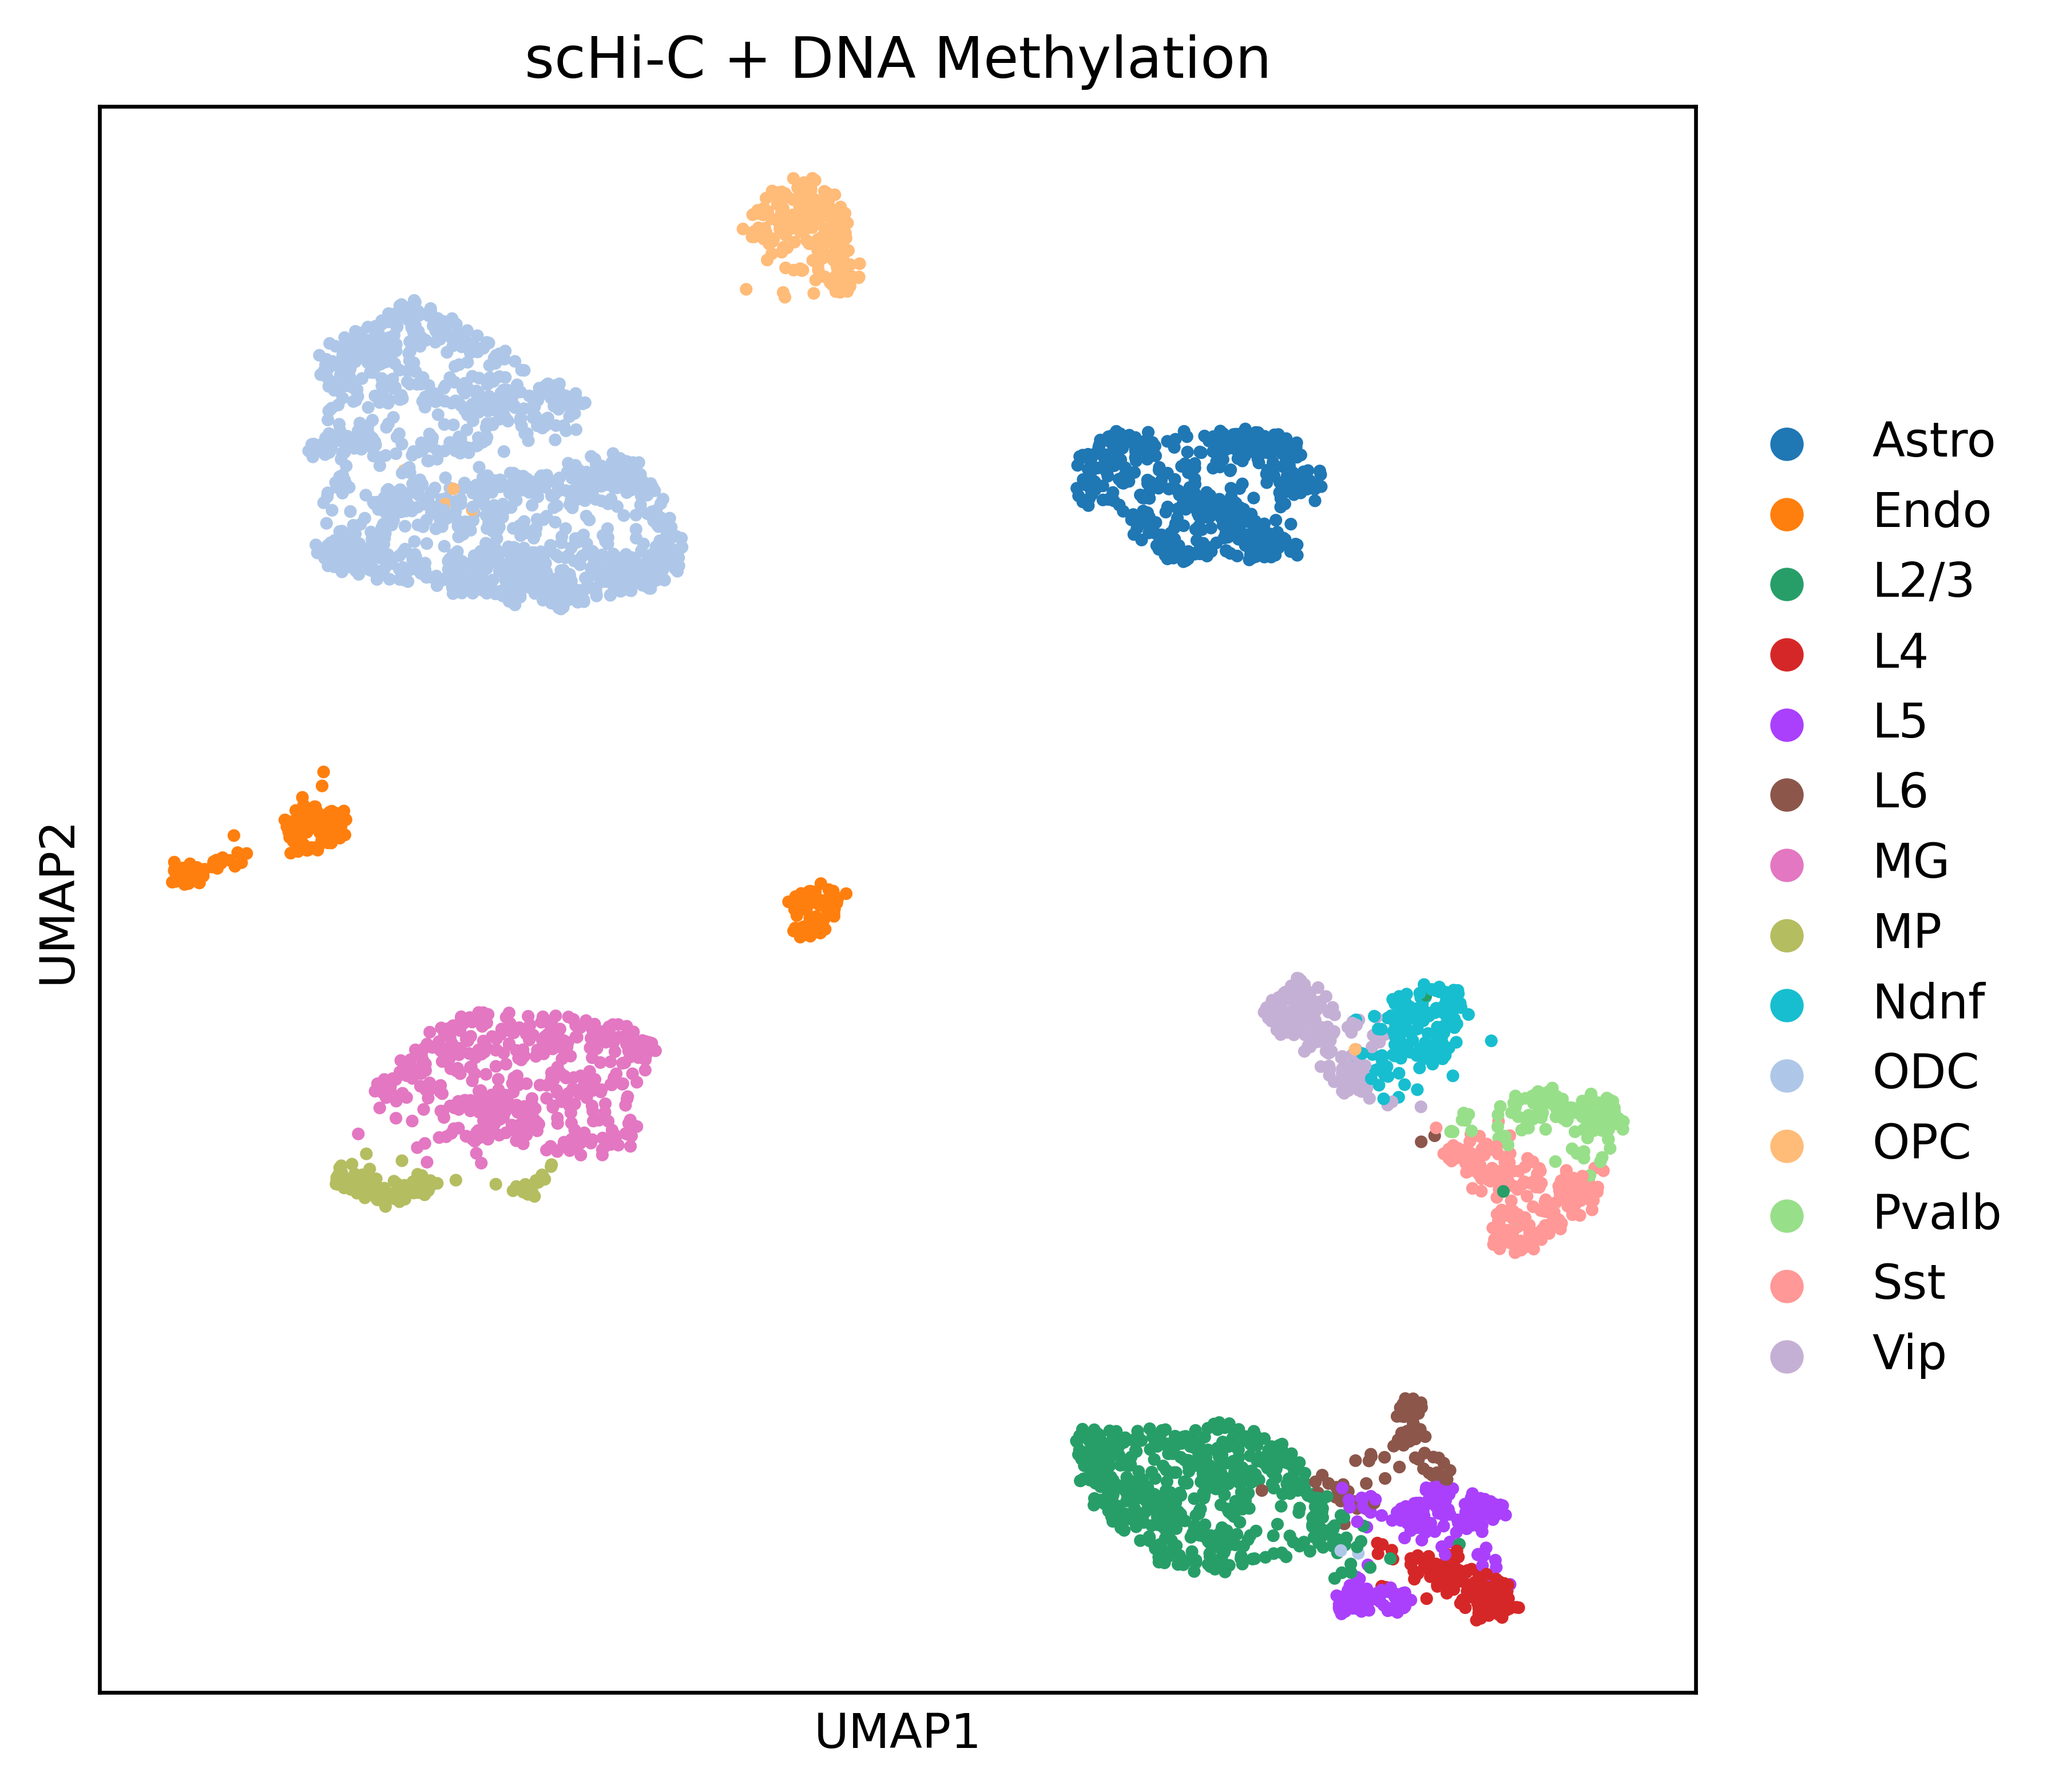

In [15]:
import scanpy as sc
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6,6), dpi=600)

sc.pl.umap(
    adata,
    color='cell_type',
    title='scHi-C + DNA Methylation',     # no title
    ax=ax,
    show=False
)

### Compute Metrics

In [16]:
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.metrics import (
    adjusted_rand_score, adjusted_mutual_info_score, normalized_mutual_info_score,
    accuracy_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix
import scib_metrics
from tqdm.notebook import tqdm # For a nice progress bar during the sweep

# --- HELPER FUNCTION ---
def map_clusters_to_ground_truth(y_true, y_pred):
    ct = pd.crosstab(y_pred, y_true)
    mapping_dict = ct.idxmax(axis=1).to_dict()
    return np.array([mapping_dict.get(val, "Unmapped") for val in y_pred])

# --- PREPARE DATA ---
X = adata.X
X_umap_2d = adata.obsm['X_umap']
y_true_str = adata.obs['cell_type'].astype(str).values
y_int = pd.Categorical(y_true_str).codes
n_cells = X.shape[0]

# --- 1. SPATIAL METRICS ---
print("Calculating Spatial Metrics (Silhouette, DBI, CHI)...")
sil_emb  = silhouette_score(X, y_true_str)
sil_umap = silhouette_score(X_umap_2d, y_true_str)
dbi      = davies_bouldin_score(X, y_true_str)
chi      = calinski_harabasz_score(X, y_true_str)

# --- 2. EXACT HYPERPARAMETER SWEEP ---
print("Running Rigorous Hyperparameter Sweep for Best & Average Metrics...")
sqrt_n = int(np.sqrt(n_cells))
min_nn, max_nn = max(10, sqrt_n // 2), min(n_cells - 1, sqrt_n * 2)
n_neighbors_list = np.unique(np.linspace(min_nn, max_nn, num=10, dtype=int))
resolutions = np.arange(0.1, 5.1, 0.1)

best_ari = -1.0
best_metrics = {}

# 🌟 NEW: List to track all configurations for the Top 5 Averages
all_sweep_results = []

# Sweeping through the grid
for nn in tqdm(n_neighbors_list, desc="Neighbors Sweep"):
    sc.pp.neighbors(adata, n_neighbors=nn, use_rep='X', metric='euclidean')
    for res in resolutions:
        key = f"leiden_nn{nn}_r{res:.1f}"
        sc.tl.leiden(adata, resolution=res, key_added=key)
        
        y_pred = adata.obs[key].values
        y_pred_mapped = map_clusters_to_ground_truth(y_true_str, y_pred)
        
        # Calculate current metrics
        current_ari = adjusted_rand_score(y_true_str, y_pred_mapped)
        current_nmi = normalized_mutual_info_score(y_true_str, y_pred_mapped)
        current_ami = adjusted_mutual_info_score(y_true_str, y_pred_mapped)
        
        current_raw_ari = adjusted_rand_score(y_true_str, y_pred)
        current_raw_nmi = normalized_mutual_info_score(y_true_str, y_pred)
        current_raw_ami = adjusted_mutual_info_score(y_true_str, y_pred)
        
        # 🌟 NEW: Save to our tracking list
        all_sweep_results.append({
            'ARI': current_ari,
            'NMI': current_nmi,
            'AMI': current_ami,
            'Raw_ARI': current_raw_ari,
            'Raw_NMI': current_raw_nmi,
            'Raw_AMI': current_raw_ami
        })
        
        # Keep the metrics from the sweep that produces the highest ARI
        if current_ari > best_ari:
            best_ari = current_ari
            best_metrics = {
                "Best n_neighbors": nn,
                "Best resolution": res,
                "ARI": current_ari,
                "NMI": current_nmi,
                "AMI": current_ami,
                "Accuracy": accuracy_score(y_true_str, y_pred_mapped)
            }

# 🌟 NEW: Calculate the Top 5 Averages using Pandas
df_sweep = pd.DataFrame(all_sweep_results)
avg_ari = df_sweep['ARI'].nlargest(5).mean()
avg_nmi = df_sweep['NMI'].nlargest(5).mean()
avg_ami = df_sweep['AMI'].nlargest(5).mean()

avg_raw_ari = df_sweep['Raw_ARI'].nlargest(5).mean()
avg_raw_nmi = df_sweep['Raw_NMI'].nlargest(5).mean()
avg_raw_ami = df_sweep['Raw_AMI'].nlargest(5).mean()

# --- 3. SCIB METRICS ---
print("Calculating SCIB Metrics (ASW & cLISI)...")
adata_3d = adata.copy()
sc.tl.umap(adata_3d, n_components=3)
raw_asw = float(silhouette_score(adata_3d.obsm['X_umap'], y_int))
asw_score = (raw_asw + 1.0) / 2.0

nbrs = NearestNeighbors(n_neighbors=50, metric='euclidean').fit(X)
distances, indices = nbrs.kneighbors(X)
distances = np.maximum(distances, 1e-12)

row = np.repeat(np.arange(n_cells), 50)
col = indices.flatten()
dist_mat = csr_matrix((distances.flatten(), (row, col)), shape=(n_cells, n_cells))
clisi_score = float(scib_metrics.clisi_knn(dist_mat, y_int))

# --- SUMMARY DATAFRAME ---
final_results = {
    "ARI": best_metrics["ARI"],
    "NMI": best_metrics["NMI"],
    "AMI": best_metrics["AMI"],
    "Average ARI (Top 5)": avg_ari,     
    "Average NMI (Top 5)": avg_nmi,     
    "Average AMI (Top 5)": avg_ami,               
    "SCIB: Cell-Type ASW": asw_score,
    "SCIB: Graph cLISI": clisi_score,
    "Sweep Config: n_neighbors": best_metrics["Best n_neighbors"],
    "Sweep Config: resolution": best_metrics["Best resolution"]
}

df_metrics = pd.DataFrame(list(final_results.items()), columns=["Metric", "Score"])
df_metrics.set_index("Metric", inplace=True)

print("\n✅ Metrics Generation Complete!")
display(df_metrics)

Calculating Spatial Metrics (Silhouette, DBI, CHI)...
Running Rigorous Hyperparameter Sweep for Best & Average Metrics...


Neighbors Sweep:   0%|          | 0/10 [00:00<?, ?it/s]

/mnt/hpcscratch/nodescratch/login02/ipykernel_509243/1342841367.py:51: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=res, key_added=key)


Calculating SCIB Metrics (ASW & cLISI)...


I0000 00:00:1783117725.511633  509243 tfrt_cpu_pjrt_client.cc:349] TfrtCpuClient created.
No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)



✅ Metrics Generation Complete!


,Score
Metric,
ARI,0.971361
NMI,0.950937
AMI,0.950491
Average ARI (Top 5),0.971216
Average NMI (Top 5),0.950858
Average AMI (Top 5),0.950411
SCIB: Cell-Type ASW,0.772843
SCIB: Graph cLISI,1.000000
Sweep Config: n_neighbors,108.000000


### Downstream Analysis

In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import pdist

def _soft_diverging():
    return LinearSegmentedColormap.from_list("soft_div",
                                             ["#2b6da5", "#f7f7f7", "#b84a48"], N=256)

def _auto_palette(categories):
    cats = pd.Index(categories).unique().tolist()
    cmap = plt.get_cmap("tab20")
    return {c: cmap(i % 20) for i, c in enumerate(cats)}

def _natural_sort_columns(cols):
    import re
    def key(c):
        m = re.search(r"\d+", str(c))
        return (float('inf') if m is None else int(m.group()), str(c))
    return list(sorted(cols, key=key))

def plot_global_scores_heatmap_compact(
    global_scores: pd.DataFrame,
    cell_types: pd.Series,
    *,
    title="Factors",
    figsize=(10, 5.8),
    dpi=600,
    cmap=None,
    fixed_limits=(-0.04, 0.04),
    factor_ticks_every=5,
    show_row_dend=False,
    # column control
    col_order="first_n",      # "cluster" | "first_n" | "cluster_first_n" | "dataframe"
    n_factors=20,
    label_by_rank=True,
    show_all_factors=True,
    x_tick_fontsize=6,
    x_tick_rotation=0,
    # row / cell-type control
    row_order="by_celltype",  # "by_celltype" | "cluster_within_celltype" | "cluster"
    row_metric="euclidean",
    celltype_order=None,      # list[str]
    celltype_colors=None,     # dict[str, str]
    # NEW: Level-1 group strip
    level1_map=None,          # dict: {celltype -> L1 group}, e.g. {"L2/3":"Excitatory", ...}
    level1_order=None,        # list[str] order for L1 groups
    level1_colors=None,       # dict: {L1 group -> color}
    # saving
    #save_stem="global_scores_heatmap_compact",
    #save_png=True,
    #save_pdf=True,
):
    assert len(global_scores) == len(cell_types)

    # ---------- choose columns ----------
    if col_order in {"first_n", "cluster_first_n"}:
        cols = _natural_sort_columns(list(global_scores.columns))
        if n_factors is not None: cols = cols[:n_factors]
        cols_selected = cols
    elif col_order == "dataframe":
        cols_selected = list(global_scores.columns)
    else:
        cols_selected = list(global_scores.columns)

    X = global_scores[cols_selected].values.astype(float)

    # ---------- cell-type categories & palette ----------
    uniq_ct = list(pd.Index(cell_types.unique()))
    if celltype_order:
        cats = [c for c in celltype_order if c in uniq_ct] + [c for c in uniq_ct if c not in celltype_order]
    else:
        cats = uniq_ct

    if celltype_colors:
        ct_map = {c: celltype_colors.get(c, "#808080") for c in cats}
    else:
        ct_map = _auto_palette(cats)

    ct_codes_all = pd.Categorical(cell_types, categories=cats, ordered=True).codes

    # ---------- row ordering ----------
    if row_order == "cluster":
        if X.shape[0] >= 2:
            row_Z = linkage(pdist(X, row_metric), method="average")
            row_ord = leaves_list(row_Z)
        else:
            row_ord = np.arange(X.shape[0])

    elif row_order == "cluster_within_celltype":
        idx_blocks = []
        for ci, ct in enumerate(cats):
            idx = np.where(ct_codes_all == ci)[0]
            if len(idx) == 0:
                continue
            if len(idx) >= 2:
                Z = linkage(pdist(X[idx], row_metric), method="average")
                ord_local = idx[leaves_list(Z)]
            else:
                ord_local = idx
            idx_blocks.append(ord_local)
        row_ord = np.concatenate(idx_blocks) if idx_blocks else np.arange(X.shape[0])

    else:  # "by_celltype"
        row_ord = np.argsort(ct_codes_all, kind="mergesort")

    # ---------- column ordering ----------
    show_col_dend = False
    if col_order in {"cluster", "cluster_first_n"} and X.shape[1] >= 2:
        col_d = pdist(X.T, "correlation")
        col_d = np.nan_to_num(col_d, nan=0.0, posinf=0.0, neginf=0.0)
        col_Z = linkage(col_d, method="average")
        col_ord = leaves_list(col_Z)
        show_col_dend = True
    else:
        col_ord = np.arange(X.shape[1])

    # ---------- reorder & prep visuals ----------
    Xr = X[row_ord][:, col_ord]
    ct_sorted = cell_types.iloc[row_ord].reset_index(drop=True)

    if cmap is None: cmap = _soft_diverging()
    vmin, vmax = fixed_limits

    # Level-2 (cell-type) strip
    code_l2 = pd.Categorical(ct_sorted, categories=cats, ordered=True).codes.reshape(-1, 1)
    strip_cmap_l2 = ListedColormap([ct_map[c] for c in cats])

    # Level-1 (class) strip
    if level1_map is None:
        # simple default: everything → "All"
        l1_series = pd.Series(["All"] * len(ct_sorted), index=ct_sorted.index)
        l1_order = ["All"]
        l1_colors = {"All": "#999999"}
    else:
        l1_series = ct_sorted.map(level1_map).fillna("Other")
        uniq_l1 = list(pd.Index(l1_series.unique()))
        if level1_order:
            l1_order = [g for g in level1_order if g in uniq_l1] + [g for g in uniq_l1 if g not in level1_order]
        else:
            l1_order = uniq_l1
        if level1_colors:
            l1_colors = {g: level1_colors.get(g, "#777777") for g in l1_order}
        else:
            # pleasant 3-class default
            default = ["#d73027", "#4575b4", "#31a354", "#756bb1", "#e6550d"]
            l1_colors = {g: default[i % len(default)] for i, g in enumerate(l1_order)}

    code_l1 = pd.Categorical(l1_series, categories=l1_order, ordered=True).codes.reshape(-1, 1)
    strip_cmap_l1 = ListedColormap([l1_colors[g] for g in l1_order])

    # ---------- layout (add a second strip column) ----------
    fig = plt.figure(figsize=figsize, facecolor="white")
    gs = gridspec.GridSpec(
        nrows=7, ncols=7, figure=fig,
        # pad | heatmap | L2 strip | L1 strip | spacer | legend | pad
        width_ratios=[0.05, 10.6, 0.28, 0.28, 0.18, 1.85, 0.06],
        height_ratios=[0.55, 0.35, 0.30, 9.8, 0.35, 0.85, 0.65],
        wspace=0.03, hspace=0.03
    )

    # column dendrogram
    ax_col = fig.add_subplot(gs[1, 1]); ax_col.set_axis_off()
    if show_col_dend:
        d = dendrogram(col_Z, no_labels=True, color_threshold=0,
                       above_threshold_color="#888888", ax=ax_col)
        for c in ax_col.collections: c.set_linewidth(0.6)

    # main heatmap
    ax = fig.add_subplot(gs[3, 1])
    im = ax.imshow(Xr, aspect="auto", interpolation="nearest",
                   cmap=cmap, vmin=vmin, vmax=vmax)

    cols_ordered = np.array(cols_selected)[col_ord]
    xticklabels = (np.arange(1, len(cols_ordered) + 1)
                   if label_by_rank else cols_ordered)
    ticks = np.arange(Xr.shape[1]) if show_all_factors else np.arange(Xr.shape[1])[::max(1, factor_ticks_every)]
    ax.set_xticks(ticks)
    ax.set_xticklabels(np.array(xticklabels)[ticks],
                       fontsize=x_tick_fontsize, rotation=x_tick_rotation, ha="center")
    ax.set_yticks([])
    ax.set_xlabel("Factors"); ax.set_ylabel("Samples")
    for sp in ax.spines.values(): sp.set_linewidth(0.6)

    # cell-type (Level-2) strip
    ax_strip_l2 = fig.add_subplot(gs[3, 2])
    ax_strip_l2.imshow(code_l2, aspect="auto", interpolation="nearest",
                       cmap=strip_cmap_l2, vmin=0, vmax=len(cats)-1)
    ax_strip_l2.set_xticks([]); ax_strip_l2.set_yticks([])
    for sp in ax_strip_l2.spines.values(): sp.set_linewidth(0.6)

    # Level-1 strip
    ax_strip_l1 = fig.add_subplot(gs[3, 3])
    ax_strip_l1.imshow(code_l1, aspect="auto", interpolation="nearest",
                       cmap=strip_cmap_l1, vmin=0, vmax=len(l1_order)-1)
    ax_strip_l1.set_xticks([]); ax_strip_l1.set_yticks([])
    for sp in ax_strip_l1.spines.values(): sp.set_linewidth(0.6)

    # legends
    ax_leg = fig.add_subplot(gs[3, 5]); ax_leg.axis("off")
    # Level-1 legend (top)
    handles_l1 = [plt.Line2D([0],[0], marker="s", linestyle="", markersize=7,
                             markerfacecolor=l1_colors[g], markeredgecolor="none")
                  for g in l1_order]
    leg1 = ax_leg.legend(handles_l1, l1_order, title="Class (L1)",
                         loc="upper left", frameon=False, fontsize=8, title_fontsize=9,
                         handletextpad=0.4, borderaxespad=0.2, labelspacing=0.4)
    ax_leg.add_artist(leg1)
    # CellType legend (bottom)
    handles_l2 = [plt.Line2D([0],[0], marker="s", linestyle="", markersize=7,
                             markerfacecolor=ct_map[c], markeredgecolor="none")
                  for c in cats]
    ax_leg.legend(handles_l2, cats, title="CellType",
                  loc="lower left", frameon=False, fontsize=8, title_fontsize=9,
                  handletextpad=0.4, borderaxespad=0.2, labelspacing=0.4)

    # colorbar
    ax_cbar = fig.add_subplot(gs[5, 5])
    cb = fig.colorbar(im, cax=ax_cbar, orientation="horizontal")
    cb.set_ticks([vmin, 0, vmax]); cb.set_ticklabels([f"{vmin:.2f}", "0", f"{vmax:.2f}"])
    ax_cbar.set_xlabel("Global Score", labelpad=2)

    fig.suptitle(title, y=0.98, fontsize=13)

    # save
    # if save_png:
    #     fig.savefig(f"{save_stem}.png", dpi=dpi, bbox_inches="tight", pad_inches=0.05)
    # if save_pdf:
    #     fig.savefig(f"{save_stem}.pdf", bbox_inches="tight", pad_inches=0.05)

    return fig


In [18]:
# Level-1 mapping from earlier message
L1 = {
    "L2/3":"Excitatory","L4":"Excitatory","L5":"Excitatory","L6":"Excitatory",
    "Pvalb":"Inhibitory","Sst":"Inhibitory","Vip":"Inhibitory","Ndnf":"Inhibitory",
    "Astro":"Non-neuronal","OPC":"Non-neuronal","ODC":"Non-neuronal",
    "MG":"Non-neuronal","Endo":"Non-neuronal","MP":"Non-neuronal",
}
L1_order = ["Excitatory","Inhibitory","Non-neuronal"]
L1_colors = {"Excitatory":"#d73027", "Inhibitory":"#4575b4", "Non-neuronal":"#31a354"}

bio_order = ["Endo","MP","MG","Astro","OPC","ODC","L2/3","L4","L5","L6","Pvalb","Sst","Vip","Ndnf"]
ct_colors = {
    "Endo":"#1b9e77","MP":"#66c2a5","MG":"#01665e",
    "Astro":"#7570b3","OPC":"#80b1d3","ODC":"#225ea8",
    "L2/3":"#e41a1c","L4":"#fb6a4a","L5":"#fcae91","L6":"#a50f15",
    "Pvalb":"#6a3d9a","Sst":"#b2abd2","Vip":"#ff7f00","Ndnf":"#fdbf6f",
}

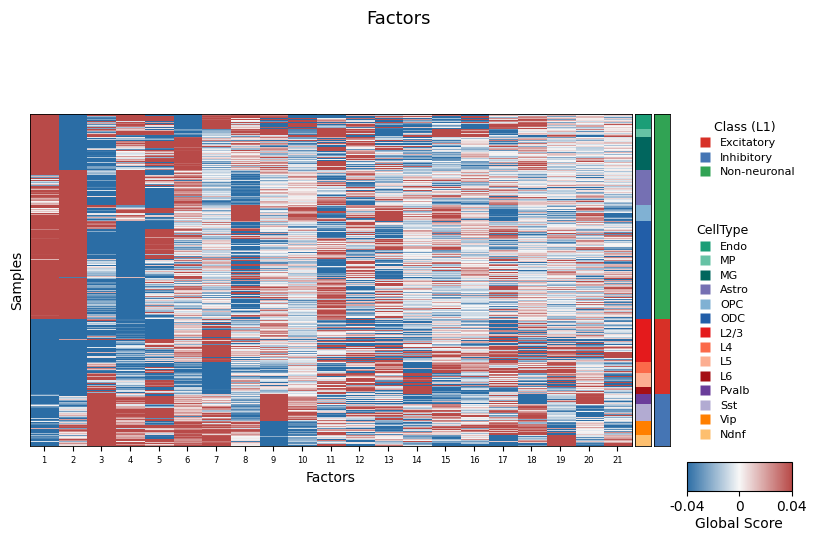

In [19]:
fig = plot_global_scores_heatmap_compact(
    global_scores,
    cell_type_information,
    cmap=None,
    fixed_limits=(-0.04, 0.04),
    dpi=600,
    # columns
    col_order="first_n", n_factors=21, label_by_rank=True, show_all_factors=True,
    # rows (keeps each cell type contiguous)
    row_order="by_celltype",
    # Level-2 styling
    celltype_order=bio_order, celltype_colors=ct_colors,
    # Level-1 strip
    level1_map=L1, level1_order=L1_order, level1_colors=L1_colors,
    # saves
    #save_stem="global_scores_heatmap_compact_with_L1",
    #save_png=True, save_pdf=True,
)

In [20]:
block_score_weights

,Unnamed: 0,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70
0,HiC,0.357371,0.322897,0.338437,0.486139,0.222621,0.417878,0.396142,0.514561,0.511218,...,0.864806,0.868027,0.866400,0.867482,0.867693,0.869228,0.856711,0.853207,0.851038,0.844645
1,SecondModality,0.933962,0.946434,0.940989,0.873881,0.974905,0.908503,0.918189,0.857454,0.859451,...,0.502106,0.496517,0.499351,0.497468,0.497100,0.494411,0.515796,0.521573,0.525105,0.535327


In [21]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from typing import Optional, Dict

def plot_block_weights_heatmap(
    weights: pd.DataFrame,
    *,
    n_factors: Optional[int] = None,          # set to 75 (or leave None to use all)
    sort_cols_by: Optional[str] = None,       # None | "variance" | a row name (e.g., "HiC")
    rename_blocks: Optional[Dict[str, str]] = None,
    figsize: Optional[tuple] = None,          # auto if None
    xtick_every: int = 5,                     # show every k factor label
    dpi: int = 600,
    cmap: str = "RdBu_r",
    out_path: Optional[str] = None
):
    df = weights.copy()

    # Move block names to index if they’re in the first column
    if "Unnamed: 0" in df.columns:
        df = df.rename(columns={"Unnamed: 0": "block"}).set_index("block")
    elif df.index.dtype != "O":
        first_col = df.columns[0]
        if df[first_col].dtype == "object":
            df = df.set_index(first_col)

    # Keep only numeric PC columns; trim to first n if requested
    num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    if n_factors is not None:
        num_cols = num_cols[:n_factors]
    df = df[num_cols]

    # Optional ordering of columns
    if sort_cols_by == "variance":
        df = df[df.var(axis=0).sort_values(ascending=False).index]
    elif sort_cols_by in df.index:
        df = df[df.loc[sort_cols_by].sort_values(ascending=False).index]

    if rename_blocks:
        df = df.rename(index=rename_blocks)

    # X tick labels: strip "PC"
    xticklabels = [re.sub(r"^PC", "", str(c)) for c in df.columns]

    # Center white at 0.5 like the R example (0..1 scale)
    norm = TwoSlopeNorm(vmin=0.0, vcenter=0.5, vmax=1.0)

    # Auto width so 75 factors fit cleanly
    if figsize is None:
        width = max(10.0, 0.16 * df.shape[1] + 3.0)  # ~0.16 in per factor
        figsize = (width, 3.6)

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(df.values, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")

    # Axes
    ax.set_yticks(np.arange(df.shape[0]))
    ax.set_yticklabels(df.index, fontsize=10)
    ax.set_xticks(np.arange(df.shape[1])[::xtick_every])
    ax.set_xticklabels(xticklabels[::xtick_every], fontsize=8)
    ax.set_xlabel("Factors", fontsize=11)
    ax.set_ylabel("")
    for sp in ax.spines.values(): sp.set_linewidth(0.6)

    # Compact vertical colorbar
    cbar = fig.colorbar(im, ax=ax, orientation="vertical", fraction=0.04, pad=0.04)
    cbar.set_label("Weight", fontsize=10)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])

    fig.suptitle("Block weights heatmap", y=0.98, fontsize=13)
    plt.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.05)
    return fig


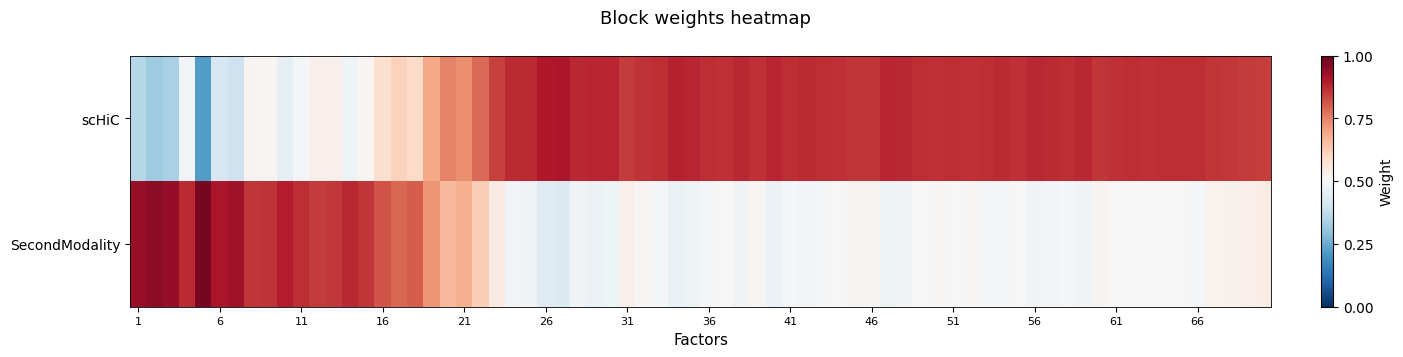

In [22]:
fig = plot_block_weights_heatmap(
    block_score_weights,
    n_factors=75,                     # or None if you only have 75 columns total
    sort_cols_by=None,                # keep PC order
    rename_blocks={"dna_met": "DNA Methylation", "HiC": "scHiC"},
    xtick_every=5,                    # show every 5th factor label
    dpi=600,
    # out_path="block_weights_75.png",
)


In [23]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Optional, Tuple

def _pick_pc(df: pd.DataFrame, pc_name: str) -> str:
    if pc_name in df.columns:
        return pc_name
    if pc_name.startswith("PC") and pc_name[2:].isdigit():
        idx = int(pc_name[2:]) - 1
        if 0 <= idx < df.shape[1]:
            return df.columns[idx]
    raise KeyError(f"{pc_name} not found. First columns: {list(df.columns[:6])}")

def _normalize_series(s: pd.Series, method: str) -> pd.Series:
    x = s.values.astype(float)
    if method == "maxabs":
        m = np.nanmax(np.abs(x)) + 1e-12
        return pd.Series(np.abs(x) / m, index=s.index)
    elif method == "minmax_abs":
        a = np.abs(x)
        lo, hi = np.nanmin(a), np.nanmax(a)
        d = (hi - lo) + 1e-12
        return pd.Series((a - lo) / d, index=s.index)
    elif method == "zscore_abs":
        a = np.abs(x)
        mu, sd = np.nanmean(a), np.nanstd(a) + 1e-12
        z = (a - mu) / sd
        # rescale to [0,1] for plotting comparability
        z = (z - np.nanmin(z)) / (np.nanmax(z) - np.nanmin(z) + 1e-12)
        return pd.Series(z, index=s.index)
    else:
        raise ValueError("method must be one of {'maxabs','minmax_abs','zscore_abs'}")

def dot_plot_top_loadings_pc_normalized(
    hic_block_loadings: pd.DataFrame,
    dna_met_block_loadings: pd.DataFrame,
    *,
    pc: str = "PC17",
    top_k: int = 15,
    norm: str = "maxabs",                     # 'maxabs' recommended
    block_names: Tuple[str, str] = ("Hi-C", "DNA_met"),
    figsize: Tuple[float, float] = (9, 3.6),
    dpi: int = 600,
    out_path: Optional[str] = None
):
    """
    Normalize the selected PC's loadings within each block, pick global top-K |loading|, and dot-plot.
    Returns (figure, table with omic, feature, loading_orig, loading_norm_signed, abs_norm).
    """
    pc_hic = _pick_pc(hic_block_loadings, pc)
    pc_dna_met = _pick_pc(dna_met_block_loadings, pc)

    # Original signed loadings
    hic_signed = hic_block_loadings[pc_hic]
    dna_met_signed = dna_met_block_loadings[pc_dna_met]

    # Normalized (per block) — we keep both signed-normalized and abs-normalized
    hic_abs_norm = _normalize_series(hic_signed, norm)
    dna_met_abs_norm = _normalize_series(dna_met_signed, norm)

    # Reapply sign to normalized magnitude for reference
    hic_norm_signed = hic_abs_norm * np.sign(hic_signed)
    dna_met_norm_signed = dna_met_abs_norm * np.sign(dna_met_signed)

    # Small oversample from each, then pick global top-K by abs_norm
    k_over = max(2 * top_k, 20)
    hic_top_idx = hic_abs_norm.nlargest(k_over).index
    dna_met_top_idx = dna_met_abs_norm.nlargest(k_over).index

    hic_df = pd.DataFrame({
        "omic": block_names[0],
        "feature": hic_top_idx.astype(str),
        "loading_orig": hic_signed.loc[hic_top_idx].values,
        "loading_norm_signed": hic_norm_signed.loc[hic_top_idx].values,
        "abs_norm": hic_abs_norm.loc[hic_top_idx].values,
    })
    dna_met_df = pd.DataFrame({
        "omic": block_names[1],
        "feature": dna_met_top_idx.astype(str),
        "loading_orig": dna_met_signed.loc[dna_met_top_idx].values,
        "loading_norm_signed": dna_met_norm_signed.loc[dna_met_top_idx].values,
        "abs_norm": dna_met_abs_norm.loc[dna_met_top_idx].values,
    })

    plot_df = pd.concat([hic_df, dna_met_df], ignore_index=True)
    plot_df = plot_df.nlargest(top_k, "abs_norm").copy()
    plot_df.sort_values("abs_norm", ascending=False, inplace=True)
    plot_df.reset_index(drop=True, inplace=True)

    # --- Plot (dot plot) ---
    fig, ax = plt.subplots(figsize=figsize)
    colors = {block_names[0]: plt.get_cmap("tab10")(0),
              block_names[1]: plt.get_cmap("tab10")(1)}
    x = np.arange(len(plot_df))
    y = plot_df["abs_norm"].values
    c = [colors[o] for o in plot_df["omic"]]

    ax.scatter(x, y, s=40, c=c)
    ax.set_ylabel(f"Normalized |loading| ({norm})")
    ax.set_xlabel("Feature")
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df["feature"].tolist(), rotation=45, ha="right", fontsize=9)
    ax.set_ylim(0, y.max() * 1.10)
    ax.margins(x=0.01)

    # legend outside (right)
    handles = [plt.Line2D([0],[0], marker="o", linestyle="", markersize=7,
                          markerfacecolor=colors[k], markeredgecolor="none")
               for k in colors]
    ax.legend(handles, list(colors.keys()), title="omic",
              frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.subplots_adjust(right=0.82)

    #ax.set_title(f"Top {top_k} normalized |loadings| for {pc}")
    factor_label = _pretty_factor_label(pc, hic_block_loadings)
    ax.set_title(f"Top {top_k} Normalized |loadings| for {factor_label}")

    if out_path:
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.05)

    # return table (include both original and normalized signed values)
    table = plot_df[["omic", "feature", "loading_orig", "loading_norm_signed", "abs_norm"]]
    return fig, table

def _pretty_factor_label(pc_name: str, df: pd.DataFrame) -> str:
    """Return 'Factor M' from a pc name like 'PC17' or 'Factor17'.
       If no digits in the name, fall back to its 1-based column index."""
    m = re.search(r"(\d+)", str(pc_name))
    if m:
        return f"Factor {int(m.group(1))}"
    if pc_name in df.columns:
        return f"Factor {list(df.columns).index(pc_name) + 1}"
    return f"{pc_name}"  # ultimate fallback

               omic feature  loading_orig  loading_norm_signed  abs_norm
0   DNA Methylation   15205      0.141490             1.000000  1.000000
1              Hi-C  114398      0.042863             1.000000  1.000000
2              Hi-C   82780      0.036529             0.852216  0.852216
3   DNA Methylation   15203      0.120061             0.848551  0.848551
4   DNA Methylation   15204      0.117904             0.833308  0.833308
5   DNA Methylation   23909      0.110597             0.781660  0.781660
6   DNA Methylation   17512      0.089523             0.632718  0.632718
7   DNA Methylation   15201      0.086273             0.609745  0.609745
8              Hi-C    8979     -0.025825            -0.602501  0.602501
9              Hi-C  130312     -0.025323            -0.590778  0.590778
10  DNA Methylation   15202      0.080014             0.565509  0.565509
11  DNA Methylation   16763     -0.072809            -0.514590  0.514590
12  DNA Methylation   21459     -0.071964          

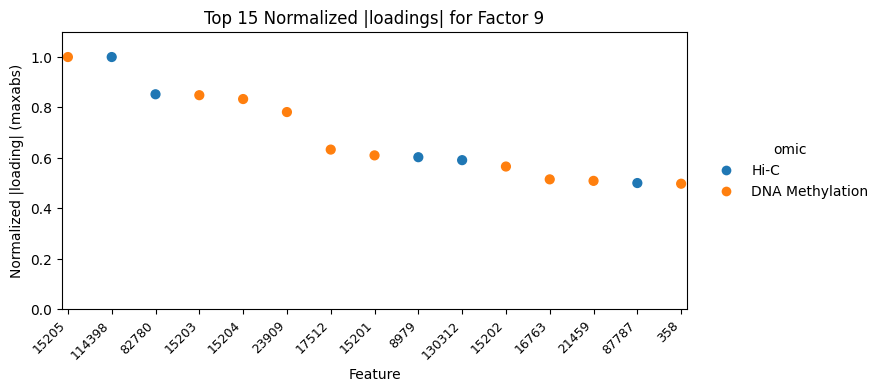

In [24]:
fig, tbl_pc9 = dot_plot_top_loadings_pc_normalized(
    hic_block_loadings,
    dna_met_block_loadings,
    pc="PC9",
    top_k=15,
    norm="maxabs",                 # or 'minmax_abs' / 'zscore_abs'
    block_names=("Hi-C", "DNA Methylation"),
    dpi=600,
    #out_path="pc9_top_norm_dotplot.pdf",
)
print(tbl_pc9)

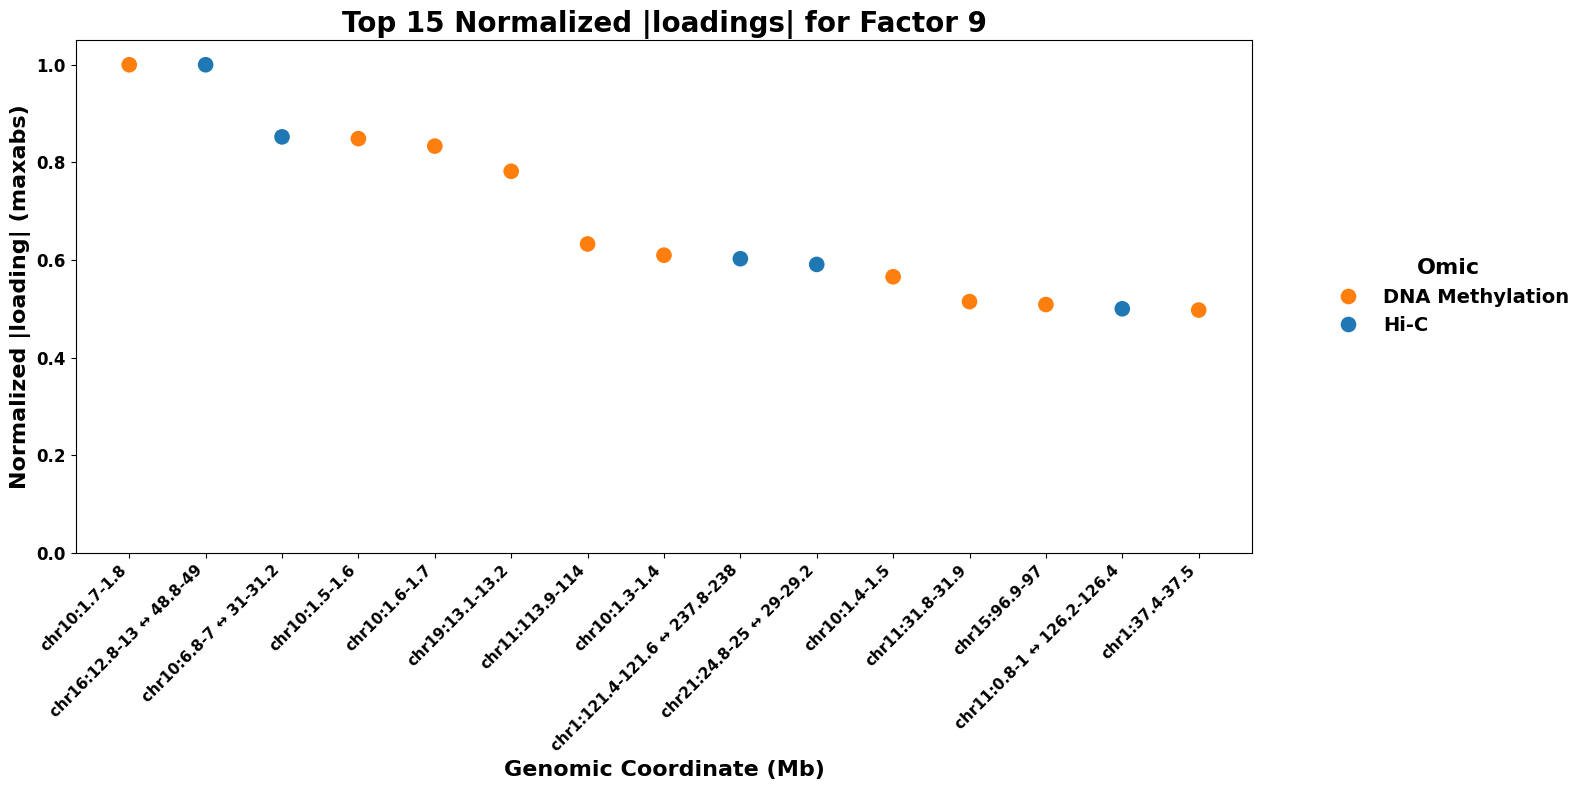

In [32]:
import os, math, numpy as np, pandas as pd
from typing import Dict, List, Optional, Tuple, Union
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. HELPER FUNCTIONS (Crash-Proofed & Row-Major Fixed)
# ==============================================================================

# Note: Adjust to the correct genome build for the Lee dataset if it isn't hg19
CHROM_SIZES_FILE = "genome_build_files/hg19.chrom.sizes.txt"
CHR_ORDER = [f"chr{i}" for i in range(1, 23)] 

def load_chrom_sizes(path: str) -> Dict[str, int]:
    sizes = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"): continue
            parts = line.split()
            if len(parts) < 2: continue
            chrom, size = parts[0], int(parts[1])
            if chrom in CHR_ORDER:
                sizes[chrom] = size
    return sizes

def _load_kept_indices(mask_path: Optional[str]) -> Optional[np.ndarray]:
    if not mask_path or not os.path.exists(mask_path): return None
    arr = np.load(mask_path, allow_pickle=False)
    if arr.dtype == bool: arr = np.flatnonzero(arr)
    else: arr = arr.astype(np.int64, copy=False)
    
    # Safety Check!
    if arr.size == 0:
        raise ValueError(f"ERROR: The mask at {mask_path} is completely empty (size 0). Check your file path!")
    return arr

def _parse_indices(indices: Union[str, List[int], np.ndarray]) -> np.ndarray:
    if isinstance(indices, (list, np.ndarray)): return np.asarray(indices, dtype=np.int64)
    txt = str(indices).replace(",", "\n").strip().split()
    return np.array([int(float(x)) for x in txt], dtype=np.int64)

def map_methylation_indices(indices, bin_size=100_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_per_chrom = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    cum_end = np.cumsum(n_per_chrom)
    cum_start = np.concatenate(([0], cum_end[:-1]))

    out = []
    for j in glob:
        c = int(np.searchsorted(cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_bin = int(j - cum_start[c])
        start = local_bin * bin_size
        end   = min((local_bin + 1) * bin_size, sizes[chrom])
        out.append((int(j), chrom, local_bin, start, end))
    return pd.DataFrame(out, columns=["global_index", "chrom", "bin", "start", "end"])

def _per_chrom_bins_and_pairs(sizes: Dict[str, int], bin_size: int):
    n_bins = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    n_pairs = n_bins * (n_bins - 1) // 2
    return n_bins, n_pairs

def map_hic_indices(indices, bin_size=200_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_bins, n_pairs = _per_chrom_bins_and_pairs(sizes, bin_size)
    pairs_cum_end = np.cumsum(n_pairs)
    pairs_cum_start = np.concatenate(([0], pairs_cum_end[:-1]))

    rows = []
    for j in glob:
        # Find which chromosome this index belongs to
        c = int(np.searchsorted(pairs_cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_k = int(j - pairs_cum_start[c])
        
        # Total bins for this specific chromosome
        N = int(n_bins[c]) 
        
        # =========================================================
        # ROW-MAJOR DECODING (Matches Python np.triu_indices)
        # =========================================================
        # Calculate Row (binA)
        binA = int((2 * N - 1 - math.sqrt((2 * N - 1)**2 - 8 * local_k)) // 2)
        
        # Calculate starting index of this row to find Column (binB)
        S_i = binA * (N - 1) - (binA * (binA - 1)) // 2
        binB = int(local_k - S_i + binA + 1)
        # =========================================================
        
        startA = binA * bin_size
        endA   = min((binA + 1) * bin_size, sizes[chrom])
        startB = binB * bin_size
        endB   = min((binB + 1) * bin_size, sizes[chrom])
        
        rows.append((int(j), chrom, binA, startA, endA, binB, startB, endB, int(binB - binA)))
        
    return pd.DataFrame(rows, columns=["global_index","chrom","binA","startA","endA","binB","startB","endB","diag"])

def lookup(omic, indices, bin_size, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    omic = omic.lower()
    if omic in ("hic","hi-c","schic","sc_hic"):
        return map_hic_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    elif omic in ("meth","methylation","dna_methylation"):
        return map_methylation_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    else:
        raise ValueError("omic must be 'hic' or 'methylation'")


# ==============================================================================
# 2. PLOTTING SCRIPT (With the Lee Dataset Paths)
# ==============================================================================

HIC_MASK = "sample_data/Preprocessed_Sample_Data/Lee_200kb_scHiC_kept_features.npy"
HIC_BIN_SIZE = 200_000

DNA_MET_MASK = "sample_data/Preprocessed_Sample_Data/Lee_dna_methylation_kept_features.npy"
DNA_MET_BIN_SIZE = 100_000

# FIX: Load your data! (Uncomment and set path if needed)
# tbl_pc9 = pd.read_csv("path_to_tbl_pc9.csv") 

plot_df = tbl_pc9.head(15).copy()

# Ensure the 'feature' column is consistently integer so mapping doesn't fail
plot_df['feature'] = plot_df['feature'].astype(float).astype(int)

hic_features = plot_df[plot_df['omic'] == 'Hi-C']['feature'].tolist()
dna_met_features = plot_df[plot_df['omic'] == 'DNA Methylation']['feature'].tolist()

# Map Hi-C features
hic_mapping = {}
if len(hic_features) > 0:
    hic_df = lookup("hic", hic_features, bin_size=HIC_BIN_SIZE, index_space="kept", kept_mask_path=HIC_MASK)
    for feat, (_, row) in zip(hic_features, hic_df.iterrows()):
        hic_mapping[feat] = f"{row['chrom']}:{row['startA']/1e6:g}-{row['endA']/1e6:g} \u2194 {row['startB']/1e6:g}-{row['endB']/1e6:g}"

# Map DNA Methylation features
dna_met_mapping = {}
if len(dna_met_features) > 0:
    dna_met_df = lookup("methylation", dna_met_features, bin_size=DNA_MET_BIN_SIZE, index_space="kept", kept_mask_path=DNA_MET_MASK)
    for feat, (_, row) in zip(dna_met_features, dna_met_df.iterrows()):
        dna_met_mapping[feat] = f"{row['chrom']}:{row['start']/1e6:g}-{row['end']/1e6:g}"

# Combine mappings and map back to dataframe
full_mapping = {**hic_mapping, **dna_met_mapping}
plot_df_mapped = plot_df.copy()
plot_df_mapped['genomic_coord'] = plot_df_mapped['feature'].map(full_mapping)

# ==============================================================================
# 3. DRAW THE PLOT 
# ==============================================================================

# Expanded canvas so labels don't get chopped off
plt.figure(figsize=(16, 8))

# Safely grab the y-axis column
y_col = plot_df_mapped.columns[2] if 'omic' in plot_df_mapped.columns[1] else plot_df_mapped.columns[-2]

sns.scatterplot(
    data=plot_df_mapped,
    x='genomic_coord',
    y=y_col,
    hue='omic',
    s=150, 
    palette={'Hi-C': '#1f77b4', 'DNA Methylation': '#ff7f0e'}
)

# Lock the y-axis scale from 0 to just above 1
plt.ylim(0, 1.05)

plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.xlabel("Genomic Coordinate (Mb)", fontsize=16, fontweight='bold')
plt.ylabel("Normalized |loading| (maxabs)", fontsize=16, fontweight='bold')
plt.title("Top 15 Normalized |loadings| for Factor 9", fontsize=20, fontweight='bold')

legend = plt.legend(
    title='Omic', 
    bbox_to_anchor=(1.05, 0.5), 
    loc='center left', 
    frameon=False,
    fontsize=14, 
    title_fontsize=16
)
plt.setp(legend.get_title(), fontweight='bold')
for text in legend.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
# plt.savefig("pc9_top_norm_dotplot_genomic.pdf", dpi=600, bbox_inches='tight')
plt.show()

### Factor 8

               omic feature  loading_orig  loading_norm_signed  abs_norm
0   DNA Methylation    1443     -0.085958            -1.000000  1.000000
1              Hi-C   65325      0.022888             1.000000  1.000000
2              Hi-C  130311      0.021517             0.940104  0.940104
3   DNA Methylation   22470     -0.078757            -0.916231  0.916231
4              Hi-C  130304      0.020864             0.911562  0.911562
5   DNA Methylation   21389     -0.070920            -0.825060  0.825060
6   DNA Methylation    4828      0.068890             0.801434  0.801434
7              Hi-C  106626      0.018272             0.798319  0.798319
8   DNA Methylation   12377     -0.068308            -0.794664  0.794664
9   DNA Methylation   21681     -0.068043            -0.791586  0.791586
10             Hi-C   93449      0.018033             0.787866  0.787866
11             Hi-C    7018      0.018002             0.786519  0.786519
12  DNA Methylation    4373     -0.067249          

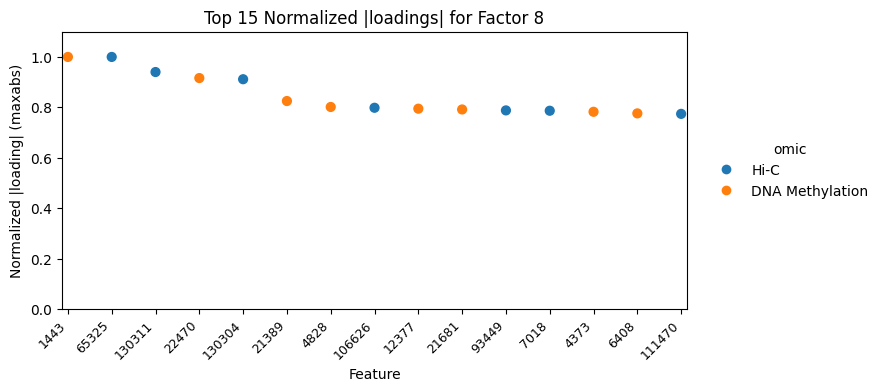

In [26]:
fig, tbl_pc8 = dot_plot_top_loadings_pc_normalized(
    hic_block_loadings,
    dna_met_block_loadings,
    pc="PC8",
    top_k=15,
    norm="maxabs",                 # or 'minmax_abs' / 'zscore_abs'
    block_names=("Hi-C", "DNA Methylation"),
    dpi=600,
    #out_path="pc9_top_norm_dotplot.pdf",
)
print(tbl_pc8)

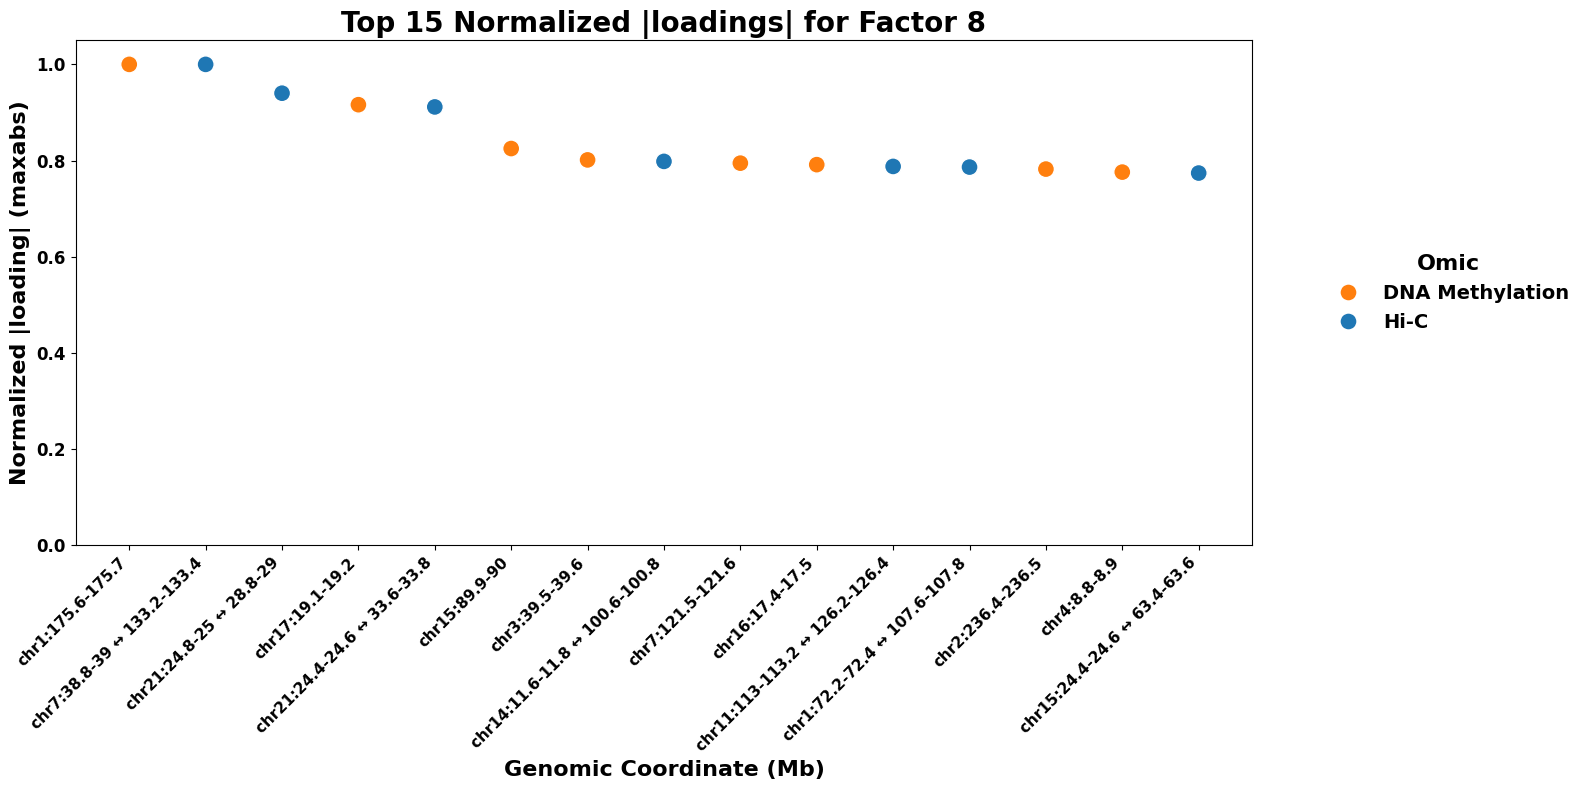

In [33]:
import os, math, numpy as np, pandas as pd
from typing import Dict, List, Optional, Tuple, Union
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. HELPER FUNCTIONS (Crash-Proofed & Row-Major Fixed)
# ==============================================================================

# Note: Adjust to the correct genome build for the Lee dataset if it isn't hg19
CHROM_SIZES_FILE = "genome_build_files/hg19.chrom.sizes.txt"
CHR_ORDER = [f"chr{i}" for i in range(1, 23)] 

def load_chrom_sizes(path: str) -> Dict[str, int]:
    sizes = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"): continue
            parts = line.split()
            if len(parts) < 2: continue
            chrom, size = parts[0], int(parts[1])
            if chrom in CHR_ORDER:
                sizes[chrom] = size
    return sizes

def _load_kept_indices(mask_path: Optional[str]) -> Optional[np.ndarray]:
    if not mask_path or not os.path.exists(mask_path): return None
    arr = np.load(mask_path, allow_pickle=False)
    if arr.dtype == bool: arr = np.flatnonzero(arr)
    else: arr = arr.astype(np.int64, copy=False)
    
    # Safety Check!
    if arr.size == 0:
        raise ValueError(f"ERROR: The mask at {mask_path} is completely empty (size 0). Check your file path!")
    return arr

def _parse_indices(indices: Union[str, List[int], np.ndarray]) -> np.ndarray:
    if isinstance(indices, (list, np.ndarray)): return np.asarray(indices, dtype=np.int64)
    txt = str(indices).replace(",", "\n").strip().split()
    return np.array([int(float(x)) for x in txt], dtype=np.int64)

def map_methylation_indices(indices, bin_size=100_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_per_chrom = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    cum_end = np.cumsum(n_per_chrom)
    cum_start = np.concatenate(([0], cum_end[:-1]))

    out = []
    for j in glob:
        c = int(np.searchsorted(cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_bin = int(j - cum_start[c])
        start = local_bin * bin_size
        end   = min((local_bin + 1) * bin_size, sizes[chrom])
        out.append((int(j), chrom, local_bin, start, end))
    return pd.DataFrame(out, columns=["global_index", "chrom", "bin", "start", "end"])

def _per_chrom_bins_and_pairs(sizes: Dict[str, int], bin_size: int):
    n_bins = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    n_pairs = n_bins * (n_bins - 1) // 2
    return n_bins, n_pairs

def map_hic_indices(indices, bin_size=200_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_bins, n_pairs = _per_chrom_bins_and_pairs(sizes, bin_size)
    pairs_cum_end = np.cumsum(n_pairs)
    pairs_cum_start = np.concatenate(([0], pairs_cum_end[:-1]))

    rows = []
    for j in glob:
        # Find which chromosome this index belongs to
        c = int(np.searchsorted(pairs_cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_k = int(j - pairs_cum_start[c])
        
        # Total bins for this specific chromosome
        N = int(n_bins[c]) 
        
        # =========================================================
        # ROW-MAJOR DECODING (Matches Python np.triu_indices)
        # =========================================================
        # Calculate Row (binA)
        binA = int((2 * N - 1 - math.sqrt((2 * N - 1)**2 - 8 * local_k)) // 2)
        
        # Calculate starting index of this row to find Column (binB)
        S_i = binA * (N - 1) - (binA * (binA - 1)) // 2
        binB = int(local_k - S_i + binA + 1)
        # =========================================================
        
        startA = binA * bin_size
        endA   = min((binA + 1) * bin_size, sizes[chrom])
        startB = binB * bin_size
        endB   = min((binB + 1) * bin_size, sizes[chrom])
        
        rows.append((int(j), chrom, binA, startA, endA, binB, startB, endB, int(binB - binA)))
        
    return pd.DataFrame(rows, columns=["global_index","chrom","binA","startA","endA","binB","startB","endB","diag"])

def lookup(omic, indices, bin_size, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    omic = omic.lower()
    if omic in ("hic","hi-c","schic","sc_hic"):
        return map_hic_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    elif omic in ("meth","methylation","dna_methylation"):
        return map_methylation_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    else:
        raise ValueError("omic must be 'hic' or 'methylation'")


# ==============================================================================
# 2. PLOTTING SCRIPT (With the Lee Dataset Paths)
# ==============================================================================

HIC_MASK = "sample_data/Preprocessed_Sample_Data/Lee_200kb_scHiC_kept_features.npy"
HIC_BIN_SIZE = 200_000

DNA_MET_MASK = "sample_data/Preprocessed_Sample_Data/Lee_dna_methylation_kept_features.npy"
DNA_MET_BIN_SIZE = 100_000

# FIX: Load your data! (Uncomment and set path if needed)
# tbl_pc9 = pd.read_csv("path_to_tbl_pc9.csv") 

plot_df = tbl_pc8.head(15).copy()

# Ensure the 'feature' column is consistently integer so mapping doesn't fail
plot_df['feature'] = plot_df['feature'].astype(float).astype(int)

hic_features = plot_df[plot_df['omic'] == 'Hi-C']['feature'].tolist()
dna_met_features = plot_df[plot_df['omic'] == 'DNA Methylation']['feature'].tolist()

# Map Hi-C features
hic_mapping = {}
if len(hic_features) > 0:
    hic_df = lookup("hic", hic_features, bin_size=HIC_BIN_SIZE, index_space="kept", kept_mask_path=HIC_MASK)
    for feat, (_, row) in zip(hic_features, hic_df.iterrows()):
        hic_mapping[feat] = f"{row['chrom']}:{row['startA']/1e6:g}-{row['endA']/1e6:g} \u2194 {row['startB']/1e6:g}-{row['endB']/1e6:g}"

# Map DNA Methylation features
dna_met_mapping = {}
if len(dna_met_features) > 0:
    dna_met_df = lookup("methylation", dna_met_features, bin_size=DNA_MET_BIN_SIZE, index_space="kept", kept_mask_path=DNA_MET_MASK)
    for feat, (_, row) in zip(dna_met_features, dna_met_df.iterrows()):
        dna_met_mapping[feat] = f"{row['chrom']}:{row['start']/1e6:g}-{row['end']/1e6:g}"

# Combine mappings and map back to dataframe
full_mapping = {**hic_mapping, **dna_met_mapping}
plot_df_mapped = plot_df.copy()
plot_df_mapped['genomic_coord'] = plot_df_mapped['feature'].map(full_mapping)

# ==============================================================================
# 3. DRAW THE PLOT 
# ==============================================================================

# Expanded canvas so labels don't get chopped off
plt.figure(figsize=(16, 8))

# Safely grab the y-axis column
y_col = plot_df_mapped.columns[2] if 'omic' in plot_df_mapped.columns[1] else plot_df_mapped.columns[-2]

sns.scatterplot(
    data=plot_df_mapped,
    x='genomic_coord',
    y=y_col,
    hue='omic',
    s=150, 
    palette={'Hi-C': '#1f77b4', 'DNA Methylation': '#ff7f0e'}
)

# Lock the y-axis scale from 0 to just above 1
plt.ylim(0, 1.05)

plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.xlabel("Genomic Coordinate (Mb)", fontsize=16, fontweight='bold')
plt.ylabel("Normalized |loading| (maxabs)", fontsize=16, fontweight='bold')
plt.title("Top 15 Normalized |loadings| for Factor 8", fontsize=20, fontweight='bold')

legend = plt.legend(
    title='Omic', 
    bbox_to_anchor=(1.05, 0.5), 
    loc='center left', 
    frameon=False,
    fontsize=14, 
    title_fontsize=16
)
plt.setp(legend.get_title(), fontweight='bold')
for text in legend.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
# plt.savefig("pc9_top_norm_dotplot_genomic.pdf", dpi=600, bbox_inches='tight')
plt.show()

### Factor 17

               omic feature  loading_orig  loading_norm_signed  abs_norm
0   DNA Methylation    6624     -0.045278            -1.000000  1.000000
1              Hi-C  127720     -0.018154            -1.000000  1.000000
2   DNA Methylation   24948      0.043324             0.956836  0.956836
3   DNA Methylation   18775      0.043272             0.955705  0.955705
4   DNA Methylation   10761     -0.042679            -0.942591  0.942591
5              Hi-C   65433     -0.016988            -0.935798  0.935798
6   DNA Methylation   20657      0.041799             0.923160  0.923160
7   DNA Methylation   13588     -0.039129            -0.864187  0.864187
8   DNA Methylation   20739      0.036743             0.811493  0.811493
9   DNA Methylation    4555     -0.036555            -0.807339  0.807339
10  DNA Methylation   23530     -0.036530            -0.806800  0.806800
11  DNA Methylation    1713     -0.036246            -0.800518  0.800518
12  DNA Methylation    6310     -0.036087          

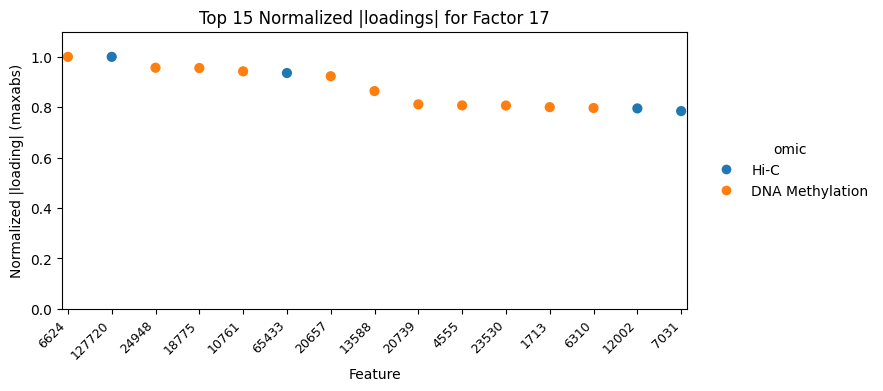

In [29]:
fig, tbl_pc17 = dot_plot_top_loadings_pc_normalized(
    hic_block_loadings,
    dna_met_block_loadings,
    pc="PC17",
    top_k=15,
    norm="maxabs",                 # or 'minmax_abs' / 'zscore_abs'
    block_names=("Hi-C", "DNA Methylation"),
    dpi=600,
    #out_path="pc9_top_norm_dotplot.pdf",
)
print(tbl_pc17)

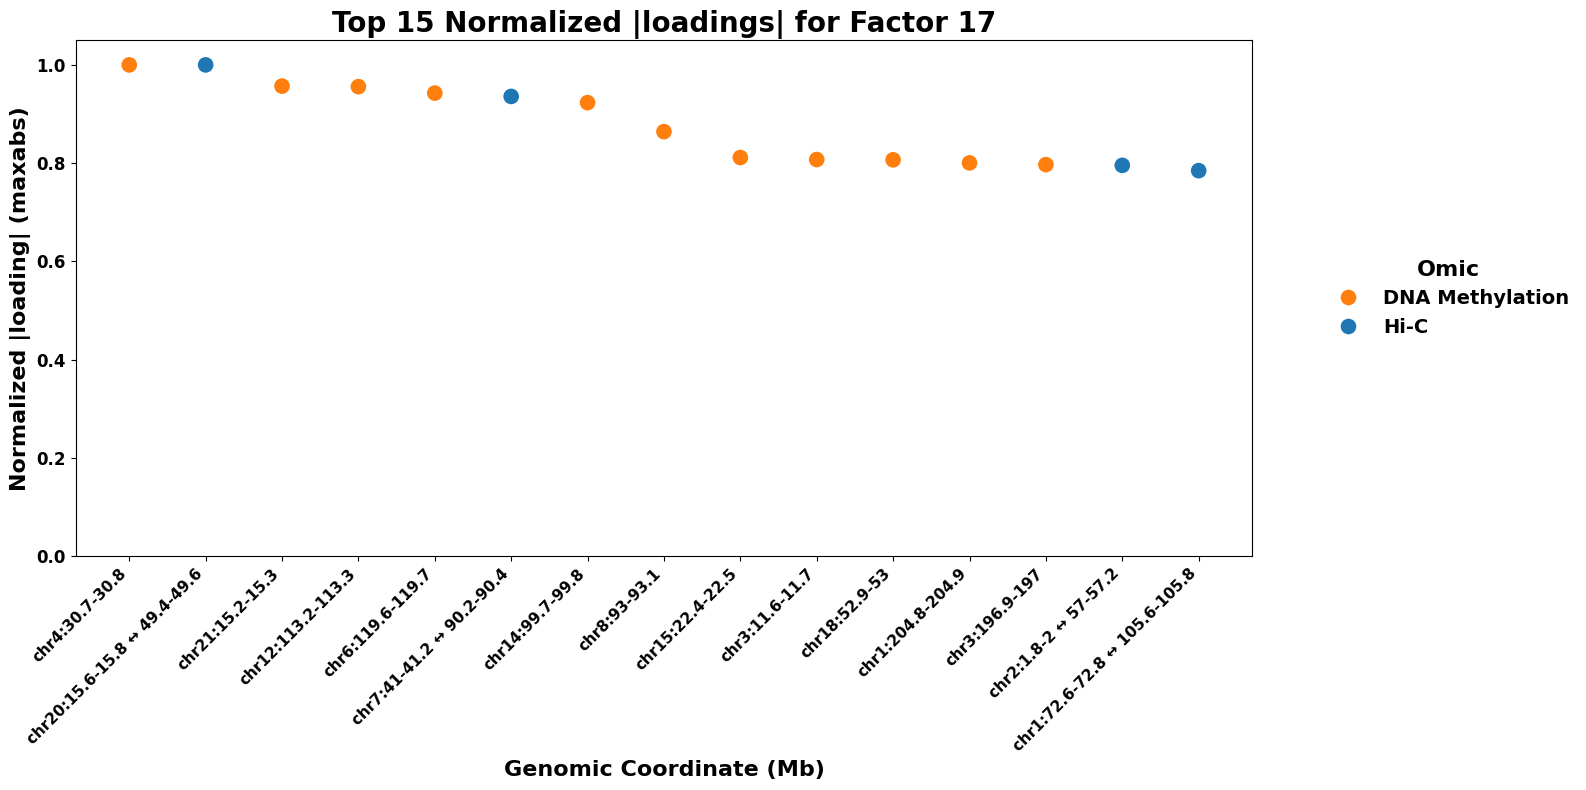

In [34]:
import os, math, numpy as np, pandas as pd
from typing import Dict, List, Optional, Tuple, Union
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. HELPER FUNCTIONS (Crash-Proofed & Row-Major Fixed)
# ==============================================================================

# Note: Adjust to the correct genome build for the Lee dataset if it isn't hg19
CHROM_SIZES_FILE = "genome_build_files/hg19.chrom.sizes.txt"
CHR_ORDER = [f"chr{i}" for i in range(1, 23)] 

def load_chrom_sizes(path: str) -> Dict[str, int]:
    sizes = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"): continue
            parts = line.split()
            if len(parts) < 2: continue
            chrom, size = parts[0], int(parts[1])
            if chrom in CHR_ORDER:
                sizes[chrom] = size
    return sizes

def _load_kept_indices(mask_path: Optional[str]) -> Optional[np.ndarray]:
    if not mask_path or not os.path.exists(mask_path): return None
    arr = np.load(mask_path, allow_pickle=False)
    if arr.dtype == bool: arr = np.flatnonzero(arr)
    else: arr = arr.astype(np.int64, copy=False)
    
    # Safety Check!
    if arr.size == 0:
        raise ValueError(f"ERROR: The mask at {mask_path} is completely empty (size 0). Check your file path!")
    return arr

def _parse_indices(indices: Union[str, List[int], np.ndarray]) -> np.ndarray:
    if isinstance(indices, (list, np.ndarray)): return np.asarray(indices, dtype=np.int64)
    txt = str(indices).replace(",", "\n").strip().split()
    return np.array([int(float(x)) for x in txt], dtype=np.int64)

def map_methylation_indices(indices, bin_size=100_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_per_chrom = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    cum_end = np.cumsum(n_per_chrom)
    cum_start = np.concatenate(([0], cum_end[:-1]))

    out = []
    for j in glob:
        c = int(np.searchsorted(cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_bin = int(j - cum_start[c])
        start = local_bin * bin_size
        end   = min((local_bin + 1) * bin_size, sizes[chrom])
        out.append((int(j), chrom, local_bin, start, end))
    return pd.DataFrame(out, columns=["global_index", "chrom", "bin", "start", "end"])

def _per_chrom_bins_and_pairs(sizes: Dict[str, int], bin_size: int):
    n_bins = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    n_pairs = n_bins * (n_bins - 1) // 2
    return n_bins, n_pairs

def map_hic_indices(indices, bin_size=200_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_bins, n_pairs = _per_chrom_bins_and_pairs(sizes, bin_size)
    pairs_cum_end = np.cumsum(n_pairs)
    pairs_cum_start = np.concatenate(([0], pairs_cum_end[:-1]))

    rows = []
    for j in glob:
        # Find which chromosome this index belongs to
        c = int(np.searchsorted(pairs_cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_k = int(j - pairs_cum_start[c])
        
        # Total bins for this specific chromosome
        N = int(n_bins[c]) 
        
        # =========================================================
        # ROW-MAJOR DECODING (Matches Python np.triu_indices)
        # =========================================================
        # Calculate Row (binA)
        binA = int((2 * N - 1 - math.sqrt((2 * N - 1)**2 - 8 * local_k)) // 2)
        
        # Calculate starting index of this row to find Column (binB)
        S_i = binA * (N - 1) - (binA * (binA - 1)) // 2
        binB = int(local_k - S_i + binA + 1)
        # =========================================================
        
        startA = binA * bin_size
        endA   = min((binA + 1) * bin_size, sizes[chrom])
        startB = binB * bin_size
        endB   = min((binB + 1) * bin_size, sizes[chrom])
        
        rows.append((int(j), chrom, binA, startA, endA, binB, startB, endB, int(binB - binA)))
        
    return pd.DataFrame(rows, columns=["global_index","chrom","binA","startA","endA","binB","startB","endB","diag"])

def lookup(omic, indices, bin_size, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    omic = omic.lower()
    if omic in ("hic","hi-c","schic","sc_hic"):
        return map_hic_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    elif omic in ("meth","methylation","dna_methylation"):
        return map_methylation_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    else:
        raise ValueError("omic must be 'hic' or 'methylation'")


# ==============================================================================
# 2. PLOTTING SCRIPT (With the Lee Dataset Paths)
# ==============================================================================

HIC_MASK = "sample_data/Preprocessed_Sample_Data/Lee_200kb_scHiC_kept_features.npy"
HIC_BIN_SIZE = 200_000

DNA_MET_MASK = "sample_data/Preprocessed_Sample_Data/Lee_dna_methylation_kept_features.npy"
DNA_MET_BIN_SIZE = 100_000

# FIX: Load your data! (Uncomment and set path if needed)
# tbl_pc9 = pd.read_csv("path_to_tbl_pc9.csv") 

plot_df = tbl_pc17.head(15).copy()

# Ensure the 'feature' column is consistently integer so mapping doesn't fail
plot_df['feature'] = plot_df['feature'].astype(float).astype(int)

hic_features = plot_df[plot_df['omic'] == 'Hi-C']['feature'].tolist()
dna_met_features = plot_df[plot_df['omic'] == 'DNA Methylation']['feature'].tolist()

# Map Hi-C features
hic_mapping = {}
if len(hic_features) > 0:
    hic_df = lookup("hic", hic_features, bin_size=HIC_BIN_SIZE, index_space="kept", kept_mask_path=HIC_MASK)
    for feat, (_, row) in zip(hic_features, hic_df.iterrows()):
        hic_mapping[feat] = f"{row['chrom']}:{row['startA']/1e6:g}-{row['endA']/1e6:g} \u2194 {row['startB']/1e6:g}-{row['endB']/1e6:g}"

# Map DNA Methylation features
dna_met_mapping = {}
if len(dna_met_features) > 0:
    dna_met_df = lookup("methylation", dna_met_features, bin_size=DNA_MET_BIN_SIZE, index_space="kept", kept_mask_path=DNA_MET_MASK)
    for feat, (_, row) in zip(dna_met_features, dna_met_df.iterrows()):
        dna_met_mapping[feat] = f"{row['chrom']}:{row['start']/1e6:g}-{row['end']/1e6:g}"

# Combine mappings and map back to dataframe
full_mapping = {**hic_mapping, **dna_met_mapping}
plot_df_mapped = plot_df.copy()
plot_df_mapped['genomic_coord'] = plot_df_mapped['feature'].map(full_mapping)

# ==============================================================================
# 3. DRAW THE PLOT 
# ==============================================================================

# Expanded canvas so labels don't get chopped off
plt.figure(figsize=(16, 8))

# Safely grab the y-axis column
y_col = plot_df_mapped.columns[2] if 'omic' in plot_df_mapped.columns[1] else plot_df_mapped.columns[-2]

sns.scatterplot(
    data=plot_df_mapped,
    x='genomic_coord',
    y=y_col,
    hue='omic',
    s=150, 
    palette={'Hi-C': '#1f77b4', 'DNA Methylation': '#ff7f0e'}
)

# Lock the y-axis scale from 0 to just above 1
plt.ylim(0, 1.05)

plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.xlabel("Genomic Coordinate (Mb)", fontsize=16, fontweight='bold')
plt.ylabel("Normalized |loading| (maxabs)", fontsize=16, fontweight='bold')
plt.title("Top 15 Normalized |loadings| for Factor 17", fontsize=20, fontweight='bold')

legend = plt.legend(
    title='Omic', 
    bbox_to_anchor=(1.05, 0.5), 
    loc='center left', 
    frameon=False,
    fontsize=14, 
    title_fontsize=16
)
plt.setp(legend.get_title(), fontweight='bold')
for text in legend.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
# plt.savefig("pc9_top_norm_dotplot_genomic.pdf", dpi=600, bbox_inches='tight')
plt.show()

### Factor 19

               omic feature  loading_orig  loading_norm_signed  abs_norm
0   DNA Methylation    2744     -0.092300            -1.000000  1.000000
1              Hi-C  114398     -0.027230            -1.000000  1.000000
2              Hi-C   82780     -0.023190            -0.851623  0.851623
3   DNA Methylation   25538     -0.068553            -0.742713  0.742713
4   DNA Methylation   20520     -0.060577            -0.656302  0.656302
5   DNA Methylation   23909     -0.057393            -0.621808  0.621808
6   DNA Methylation   20172      0.056901             0.616472  0.616472
7              Hi-C   74264      0.015847             0.581984  0.581984
8              Hi-C  112051     -0.015038            -0.552251  0.552251
9              Hi-C  105802     -0.014088            -0.517379  0.517379
10             Hi-C   16288     -0.013946            -0.512170  0.512170
11             Hi-C  127382     -0.013655            -0.501472  0.501472
12             Hi-C  117346     -0.013604          

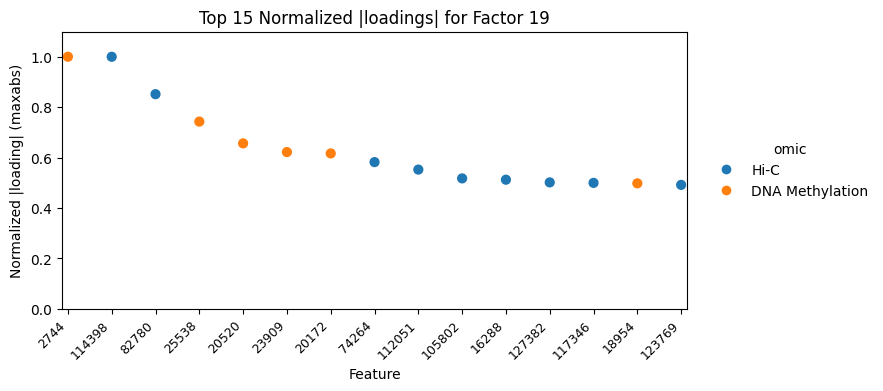

In [35]:
fig, tbl_pc19 = dot_plot_top_loadings_pc_normalized(
    hic_block_loadings,
    dna_met_block_loadings,
    pc="PC19",
    top_k=15,
    norm="maxabs",                 # or 'minmax_abs' / 'zscore_abs'
    block_names=("Hi-C", "DNA Methylation"),
    dpi=600,
    #out_path="pc9_top_norm_dotplot.pdf",
)
print(tbl_pc19)

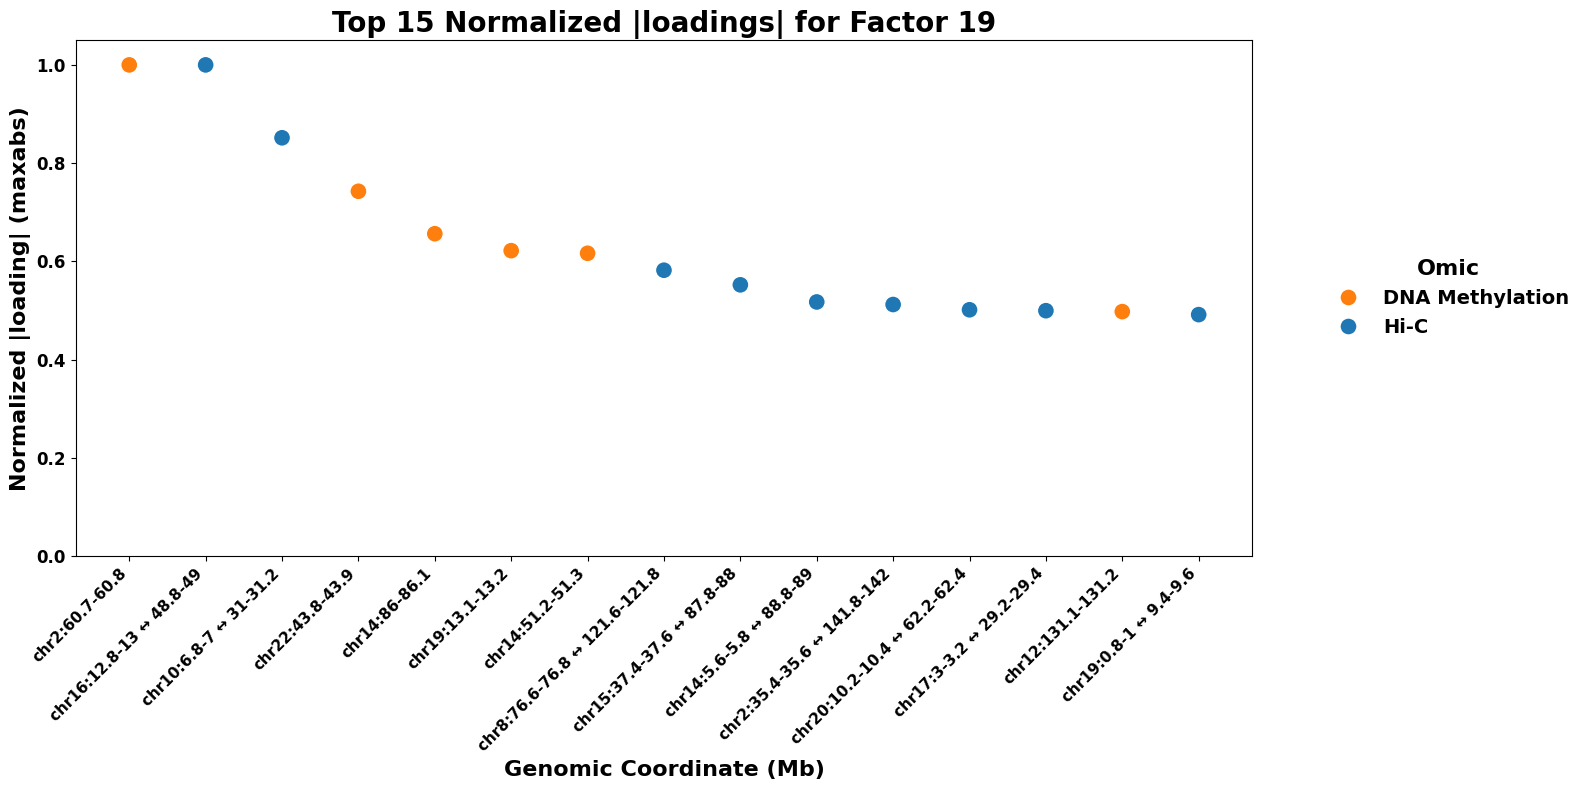

In [36]:
import os, math, numpy as np, pandas as pd
from typing import Dict, List, Optional, Tuple, Union
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. HELPER FUNCTIONS (Crash-Proofed & Row-Major Fixed)
# ==============================================================================

# Note: Adjust to the correct genome build for the Lee dataset if it isn't hg19
CHROM_SIZES_FILE = "genome_build_files/hg19.chrom.sizes.txt"
CHR_ORDER = [f"chr{i}" for i in range(1, 23)] 

def load_chrom_sizes(path: str) -> Dict[str, int]:
    sizes = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"): continue
            parts = line.split()
            if len(parts) < 2: continue
            chrom, size = parts[0], int(parts[1])
            if chrom in CHR_ORDER:
                sizes[chrom] = size
    return sizes

def _load_kept_indices(mask_path: Optional[str]) -> Optional[np.ndarray]:
    if not mask_path or not os.path.exists(mask_path): return None
    arr = np.load(mask_path, allow_pickle=False)
    if arr.dtype == bool: arr = np.flatnonzero(arr)
    else: arr = arr.astype(np.int64, copy=False)
    
    # Safety Check!
    if arr.size == 0:
        raise ValueError(f"ERROR: The mask at {mask_path} is completely empty (size 0). Check your file path!")
    return arr

def _parse_indices(indices: Union[str, List[int], np.ndarray]) -> np.ndarray:
    if isinstance(indices, (list, np.ndarray)): return np.asarray(indices, dtype=np.int64)
    txt = str(indices).replace(",", "\n").strip().split()
    return np.array([int(float(x)) for x in txt], dtype=np.int64)

def map_methylation_indices(indices, bin_size=100_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_per_chrom = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    cum_end = np.cumsum(n_per_chrom)
    cum_start = np.concatenate(([0], cum_end[:-1]))

    out = []
    for j in glob:
        c = int(np.searchsorted(cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_bin = int(j - cum_start[c])
        start = local_bin * bin_size
        end   = min((local_bin + 1) * bin_size, sizes[chrom])
        out.append((int(j), chrom, local_bin, start, end))
    return pd.DataFrame(out, columns=["global_index", "chrom", "bin", "start", "end"])

def _per_chrom_bins_and_pairs(sizes: Dict[str, int], bin_size: int):
    n_bins = np.array([math.ceil(sizes[c]/bin_size) for c in CHR_ORDER], dtype=np.int64)
    n_pairs = n_bins * (n_bins - 1) // 2
    return n_bins, n_pairs

def map_hic_indices(indices, bin_size=200_000, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    sizes = load_chrom_sizes(chrom_sizes_path)
    idx = _parse_indices(indices)
    kept_idx = _load_kept_indices(kept_mask_path)
    glob = kept_idx[idx] if index_space == "kept" and kept_idx is not None else idx

    n_bins, n_pairs = _per_chrom_bins_and_pairs(sizes, bin_size)
    pairs_cum_end = np.cumsum(n_pairs)
    pairs_cum_start = np.concatenate(([0], pairs_cum_end[:-1]))

    rows = []
    for j in glob:
        # Find which chromosome this index belongs to
        c = int(np.searchsorted(pairs_cum_end, j, side="right"))
        chrom = CHR_ORDER[c]
        local_k = int(j - pairs_cum_start[c])
        
        # Total bins for this specific chromosome
        N = int(n_bins[c]) 
        
        # =========================================================
        # ROW-MAJOR DECODING (Matches Python np.triu_indices)
        # =========================================================
        # Calculate Row (binA)
        binA = int((2 * N - 1 - math.sqrt((2 * N - 1)**2 - 8 * local_k)) // 2)
        
        # Calculate starting index of this row to find Column (binB)
        S_i = binA * (N - 1) - (binA * (binA - 1)) // 2
        binB = int(local_k - S_i + binA + 1)
        # =========================================================
        
        startA = binA * bin_size
        endA   = min((binA + 1) * bin_size, sizes[chrom])
        startB = binB * bin_size
        endB   = min((binB + 1) * bin_size, sizes[chrom])
        
        rows.append((int(j), chrom, binA, startA, endA, binB, startB, endB, int(binB - binA)))
        
    return pd.DataFrame(rows, columns=["global_index","chrom","binA","startA","endA","binB","startB","endB","diag"])

def lookup(omic, indices, bin_size, index_space="kept", kept_mask_path=None, chrom_sizes_path=CHROM_SIZES_FILE):
    omic = omic.lower()
    if omic in ("hic","hi-c","schic","sc_hic"):
        return map_hic_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    elif omic in ("meth","methylation","dna_methylation"):
        return map_methylation_indices(indices, bin_size, index_space, kept_mask_path, chrom_sizes_path)
    else:
        raise ValueError("omic must be 'hic' or 'methylation'")


# ==============================================================================
# 2. PLOTTING SCRIPT (With the Lee Dataset Paths)
# ==============================================================================

HIC_MASK = "sample_data/Preprocessed_Sample_Data/Lee_200kb_scHiC_kept_features.npy"
HIC_BIN_SIZE = 200_000

DNA_MET_MASK = "sample_data/Preprocessed_Sample_Data/Lee_dna_methylation_kept_features.npy"
DNA_MET_BIN_SIZE = 100_000

# FIX: Load your data! (Uncomment and set path if needed)
# tbl_pc9 = pd.read_csv("path_to_tbl_pc9.csv") 

plot_df = tbl_pc19.head(15).copy()

# Ensure the 'feature' column is consistently integer so mapping doesn't fail
plot_df['feature'] = plot_df['feature'].astype(float).astype(int)

hic_features = plot_df[plot_df['omic'] == 'Hi-C']['feature'].tolist()
dna_met_features = plot_df[plot_df['omic'] == 'DNA Methylation']['feature'].tolist()

# Map Hi-C features
hic_mapping = {}
if len(hic_features) > 0:
    hic_df = lookup("hic", hic_features, bin_size=HIC_BIN_SIZE, index_space="kept", kept_mask_path=HIC_MASK)
    for feat, (_, row) in zip(hic_features, hic_df.iterrows()):
        hic_mapping[feat] = f"{row['chrom']}:{row['startA']/1e6:g}-{row['endA']/1e6:g} \u2194 {row['startB']/1e6:g}-{row['endB']/1e6:g}"

# Map DNA Methylation features
dna_met_mapping = {}
if len(dna_met_features) > 0:
    dna_met_df = lookup("methylation", dna_met_features, bin_size=DNA_MET_BIN_SIZE, index_space="kept", kept_mask_path=DNA_MET_MASK)
    for feat, (_, row) in zip(dna_met_features, dna_met_df.iterrows()):
        dna_met_mapping[feat] = f"{row['chrom']}:{row['start']/1e6:g}-{row['end']/1e6:g}"

# Combine mappings and map back to dataframe
full_mapping = {**hic_mapping, **dna_met_mapping}
plot_df_mapped = plot_df.copy()
plot_df_mapped['genomic_coord'] = plot_df_mapped['feature'].map(full_mapping)

# ==============================================================================
# 3. DRAW THE PLOT 
# ==============================================================================

# Expanded canvas so labels don't get chopped off
plt.figure(figsize=(16, 8))

# Safely grab the y-axis column
y_col = plot_df_mapped.columns[2] if 'omic' in plot_df_mapped.columns[1] else plot_df_mapped.columns[-2]

sns.scatterplot(
    data=plot_df_mapped,
    x='genomic_coord',
    y=y_col,
    hue='omic',
    s=150, 
    palette={'Hi-C': '#1f77b4', 'DNA Methylation': '#ff7f0e'}
)

# Lock the y-axis scale from 0 to just above 1
plt.ylim(0, 1.05)

plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.xlabel("Genomic Coordinate (Mb)", fontsize=16, fontweight='bold')
plt.ylabel("Normalized |loading| (maxabs)", fontsize=16, fontweight='bold')
plt.title("Top 15 Normalized |loadings| for Factor 19", fontsize=20, fontweight='bold')

legend = plt.legend(
    title='Omic', 
    bbox_to_anchor=(1.05, 0.5), 
    loc='center left', 
    frameon=False,
    fontsize=14, 
    title_fontsize=16
)
plt.setp(legend.get_title(), fontweight='bold')
for text in legend.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
# plt.savefig("pc9_top_norm_dotplot_genomic.pdf", dpi=600, bbox_inches='tight')
plt.show()